# 3.3

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_image(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def show(img, title='Image'):
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(title)
    plt.axis('off')

In [2]:
img1 = load_image('leaves.png')
img2 = load_image('anh-bd-vi-tri.jpg')
img3 = load_image('seed2.png')

In [3]:
hsv1 = cv2.cvtColor(img1, cv2.COLOR_RGB2HSV)
rgb1 = cv2.cvtColor(hsv1, cv2.COLOR_HSV2RGB)
hsv2 = cv2.cvtColor(img2, cv2.COLOR_RGB2HSV)
rgb2 = cv2.cvtColor(hsv2, cv2.COLOR_HSV2RGB)
hsv3 = cv2.cvtColor(img3, cv2.COLOR_RGB2HSV)
rgb3 = cv2.cvtColor(hsv3, cv2.COLOR_HSV2RGB)

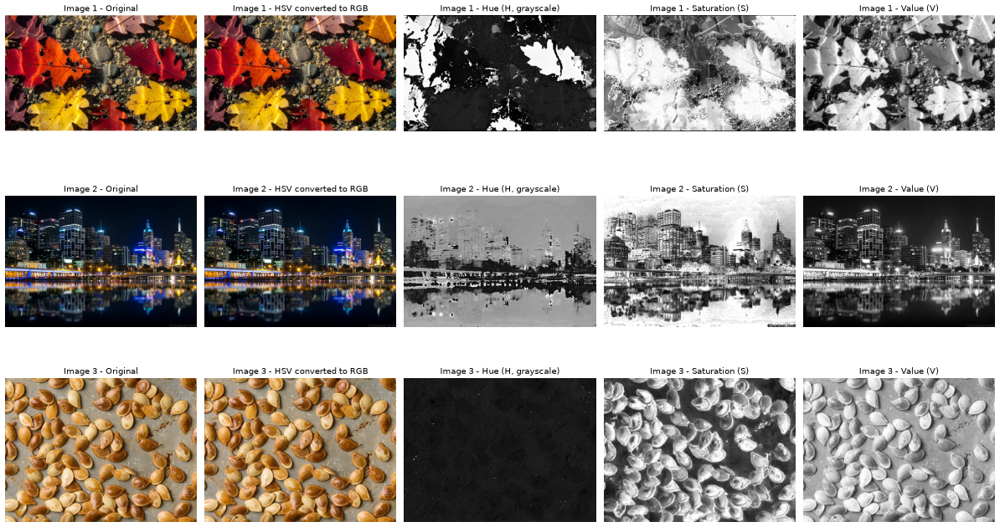

In [4]:
# Hien thi anh goc, HSV gop thanh anh mau va cac kenh H, S, V
hsv_images = [
    (img1, hsv1, "Image 1"),
    (img2, hsv2, "Image 2"),
    (img3, hsv3, "Image 3"),
]

fig, axes = plt.subplots(len(hsv_images), 5, figsize=(20, 12))

for row, (rgb, hsv, title) in enumerate(hsv_images):
    hue, saturation, value = cv2.split(hsv)
    hsv_as_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"{title} - Original")
    axes[row, 1].imshow(hsv_as_rgb)
    axes[row, 1].set_title(f"{title} - HSV converted to RGB")
    axes[row, 2].imshow(hue, cmap="gray", vmin=0, vmax=179)
    axes[row, 2].set_title(f"{title} - Hue (H, grayscale)")
    axes[row, 3].imshow(saturation, cmap="gray", vmin=0, vmax=255)
    axes[row, 3].set_title(f"{title} - Saturation (S)")
    axes[row, 4].imshow(value, cmap="gray", vmin=0, vmax=255)
    axes[row, 4].set_title(f"{title} - Value (V)")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:
def color_histogram_numpy(img):
    hist_r = np.zeros(256)
    hist_g = np.zeros(256)
    hist_b = np.zeros(256)
    for pixel in img.reshape(-1, 3):
        r, g, b = pixel
        hist_r[r] += 1
        hist_g[g] += 1
        hist_b[b] += 1
    return hist_r, hist_g, hist_b

In [6]:
histr1, histg1, histb1 = color_histogram_numpy(img1)
histr2, histg2, histb2 = color_histogram_numpy(img2)
histr3, histg3, histb3 = color_histogram_numpy(img3)

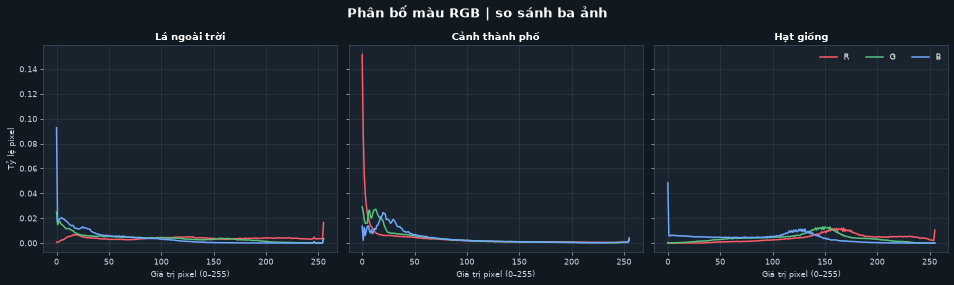

In [7]:
# Histogram RGB chuẩn hóa theo tổng pixel để so sánh được giữa ảnh khác kích thước.
image_specs = [(img1, "Lá ngoài trời", "#58c27d"), (img2, "Cảnh thành phố", "#f6bd60"), (img3, "Hạt giống", "#7aa2f7")]
channel_colors = [("R", "#ff5c68"), ("G", "#58c27d"), ("B", "#6fa8ff")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor="#101820", sharey=True)
for ax, (image, title, accent) in zip(axes, image_specs):
    for channel_index, (name, color) in enumerate(channel_colors):
        hist = np.bincount(image[..., channel_index].ravel(), minlength=256).astype(float)
        hist /= hist.sum()
        ax.plot(np.arange(256), hist, color=color, linewidth=1.8, label=name)
    ax.set_title(title, color="white", fontweight="bold")
    ax.set_xlabel("Giá trị pixel (0–255)", color="#cbd5e1")
    ax.grid(alpha=.16)
    ax.set_facecolor("#18232e")
    ax.tick_params(colors="#cbd5e1")
    ax.spines[:].set_color("#405060")
axes[0].set_ylabel("Tỷ lệ pixel", color="#cbd5e1")
axes[-1].legend(frameon=False, labelcolor="white", ncol=3, loc="upper right")
fig.suptitle("Phân bố màu RGB | so sánh ba ảnh", color="white", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()


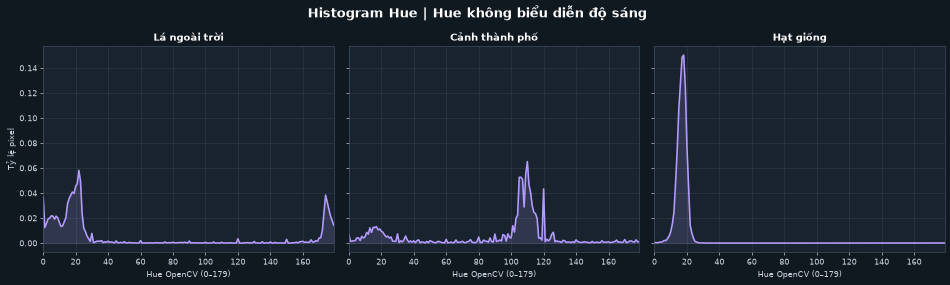

In [8]:
# So sánh phân bố Hue; chuẩn hóa mỗi histogram thành tỷ lệ để so hình dạng.
images = [(img1, hsv1, "Lá ngoài trời"), (img2, hsv2, "Cảnh thành phố"), (img3, hsv3, "Hạt giống")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor="#101820", sharey=True)
for ax, (rgb, hsv, title) in zip(axes, images):
    hue = hsv[:, :, 0]
    hue_hist = np.bincount(hue.ravel(), minlength=180).astype(float)
    hue_hist /= hue_hist.sum()
    ax.plot(np.arange(180), hue_hist, color="#b49bff", linewidth=1.9)
    ax.fill_between(np.arange(180), hue_hist, color="#b49bff", alpha=.16)
    ax.set_title(title, color="white", fontweight="bold")
    ax.set_xlabel("Hue OpenCV (0–179)", color="#cbd5e1")
    ax.set_xlim(0, 179)
    ax.grid(alpha=.16)
    ax.set_facecolor("#18232e")
    ax.tick_params(colors="#cbd5e1")
    ax.spines[:].set_color("#405060")
axes[0].set_ylabel("Tỷ lệ pixel", color="#cbd5e1")
fig.suptitle("Histogram Hue | Hue không biểu diễn độ sáng", color="white", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()


Ở đây, ảnh **Image 1** (lá ngoài trời ban ngày) được so sánh với **Image 2** (thành phố ban đêm).

Histogram H của ảnh lá có các tần suất nổi bật ở những sắc màu của lá như vàng, cam và đỏ. Ảnh thành phố ban đêm có các sắc màu từ ánh đèn vàng/cam cùng các vùng xanh lam hoặc xanh lục của cảnh thành phố. Vì vậy, hình dạng hai histogram khác nhau phản ánh thành phần màu khác nhau của hai khung cảnh.

# 4.4

In [9]:
def equalize_channel_numpy(channel_unit8):
    hist = np.bincount(channel_unit8.ravel(), minlength=256).astype(np.float64)
    cdf = hist.cumsum()
    cdf_norm = (cdf - cdf.min()) / (cdf.max() - cdf.min() + 1e-12)
    
    lut = np.floor(255 * cdf_norm).astype(np.uint8)
    out = lut[channel_unit8]
    return out
# Equalize on V
hsv1 = cv2.cvtColor(img1, cv2.COLOR_RGB2HSV)
H1, S1, V1 = cv2.split(hsv1)
V1_eq = cv2.equalizeHist(V1)
img1_v1_eq = cv2.cvtColor(cv2.merge([H1, S1, V1_eq]), cv2.COLOR_HSV2RGB)

hsv2 = cv2.cvtColor(img2, cv2.COLOR_RGB2HSV)
H2, S2, V2 = cv2.split(hsv2)
V2_eq = equalize_channel_numpy(V2)
img1_v2_eq = cv2.cvtColor(cv2.merge([H2, S2, V2_eq]), cv2.COLOR_HSV2RGB)

hsv3 = cv2.cvtColor(img3, cv2.COLOR_RGB2HSV)
H3, S3, V3 = cv2.split(hsv3)
V3_eq = equalize_channel_numpy(V3)
img1_v3_eq = cv2.cvtColor(cv2.merge([H3, S3, V3_eq]), cv2.COLOR_HSV2RGB)

# Equalize on L*
lab1 = cv2.cvtColor(img1, cv2.COLOR_RGB2LAB)
L1, A1, B1 = cv2.split(lab1)
L1_eq = cv2.equalizeHist(L1)
img1_l1_eq = cv2.cvtColor(cv2.merge([L1_eq, A1, B1]), cv2.COLOR_LAB2RGB)

lab2= cv2.cvtColor(img2, cv2.COLOR_RGB2LAB)
L2, A2, B2 = cv2.split(lab2)
L2_eq = cv2.equalizeHist(L2)
img1_l2_eq = cv2.cvtColor(cv2.merge([L2_eq, A2, B2]), cv2.COLOR_LAB2RGB)

lab3 = cv2.cvtColor(img3, cv2.COLOR_RGB2LAB)
L3, A3, B3 = cv2.split(lab3)
L3_eq = cv2.equalizeHist(L3)
img1_l3_eq = cv2.cvtColor(cv2.merge([L3_eq, A3, B3]), cv2.COLOR_LAB2RGB)

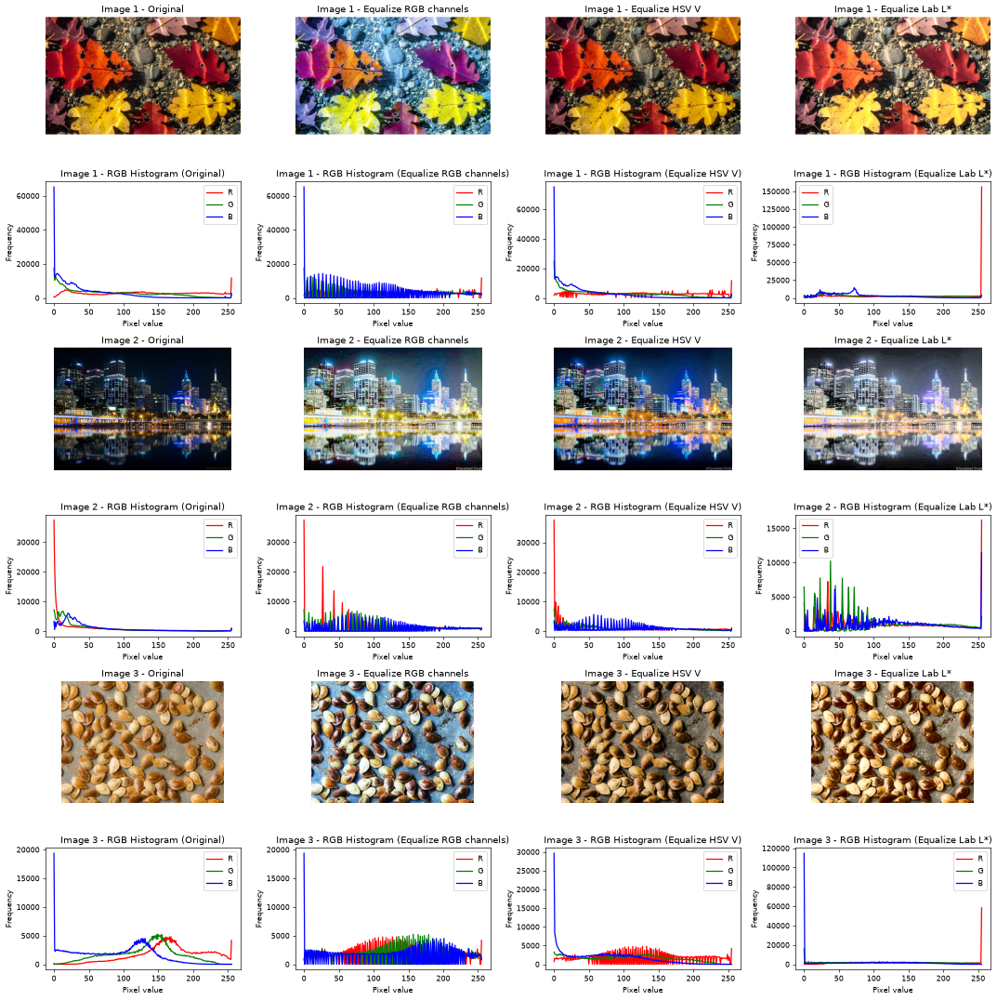

In [10]:
images = [
    (img1, "Image 1"),
    (img2, "Image 2"),
    (img3, "Image 3"),
]

fig, axes = plt.subplots(len(images) * 2, 4, figsize=(18, 18))
channel_colors = ["red", "green", "blue"]
channel_names = ["R", "G", "B"]

for row, (image, title) in enumerate(images):
    # Equalize t?ng k?nh RGB
    rgb_equalized = cv2.merge([
        cv2.equalizeHist(channel) for channel in cv2.split(image)
    ])

    # Equalize k?nh V trong HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hue, saturation, value = cv2.split(hsv)
    value_equalized = cv2.equalizeHist(value)
    hsv_equalized = cv2.cvtColor(
        cv2.merge([hue, saturation, value_equalized]),
        cv2.COLOR_HSV2RGB,
    )

    # Equalize k?nh L* trong Lab
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    lightness, a_channel, b_channel = cv2.split(lab)
    lightness_equalized = cv2.equalizeHist(lightness)
    lab_equalized = cv2.cvtColor(
        cv2.merge([lightness_equalized, a_channel, b_channel]),
        cv2.COLOR_LAB2RGB,
    )

    results = [
        (image, "Original"),
        (rgb_equalized, "Equalize RGB channels"),
        (hsv_equalized, "Equalize HSV V"),
        (lab_equalized, "Equalize Lab L*"),
    ]

    image_row = row * 2
    histogram_row = image_row + 1
    for column, (result, method) in enumerate(results):
        axes[image_row, column].imshow(result)
        axes[image_row, column].set_title(f"{title} - {method}")
        axes[image_row, column].axis("off")

        for channel_index, (channel_name, color) in enumerate(
            zip(channel_names, channel_colors)
        ):
            histogram, _ = np.histogram(
                result[:, :, channel_index], bins=256, range=(0, 256)
            )
            axes[histogram_row, column].plot(
                np.arange(256), histogram, color=color, label=channel_name
            )

        axes[histogram_row, column].set_title(f"{title} - RGB Histogram ({method})")
        axes[histogram_row, column].set_xlabel("Pixel value")
        axes[histogram_row, column].set_ylabel("Frequency")
        axes[histogram_row, column].legend()

plt.tight_layout()
plt.show()


### Nhận xét — So sánh ba cách cân bằng histogram

Quan sát ảnh và histogram RGB sau xử lý:

- **Equalize riêng từng kênh RGB:** phân bố các kênh thay đổi độc lập. Trong output, ảnh lá và ảnh hạt bị ám xanh/tím rõ; ảnh thành phố cũng sáng gắt hơn. Histogram trải ra trên nhiều mức, nhưng một số kênh có đỉnh lớn sát 255, cho thấy nhiều pixel bị dồn về vùng sáng.
- **Equalize kênh V trong HSV:** sắc màu của ba ảnh được giữ tương đối gần ảnh gốc hơn, trong khi độ tương phản thay đổi. Histogram RGB vẫn thay đổi vì V đã được cân bằng rồi chuyển lại sang RGB.
- **Equalize kênh L* trong Lab:** màu tổng thể được giữ tốt hơn so với equalize từng kênh RGB, nhưng ảnh sáng hơn; output có đỉnh lớn ở mức 255, đặc biệt ở các kênh đỏ hoặc xanh dương.

Với các ảnh trong bài, equalize riêng RGB gây lệch màu dễ thấy nhất. HSV-V giữ màu tự nhiên khá tốt; Lab-L* làm sáng ảnh rõ và có thể làm mất chi tiết ở vùng sáng.

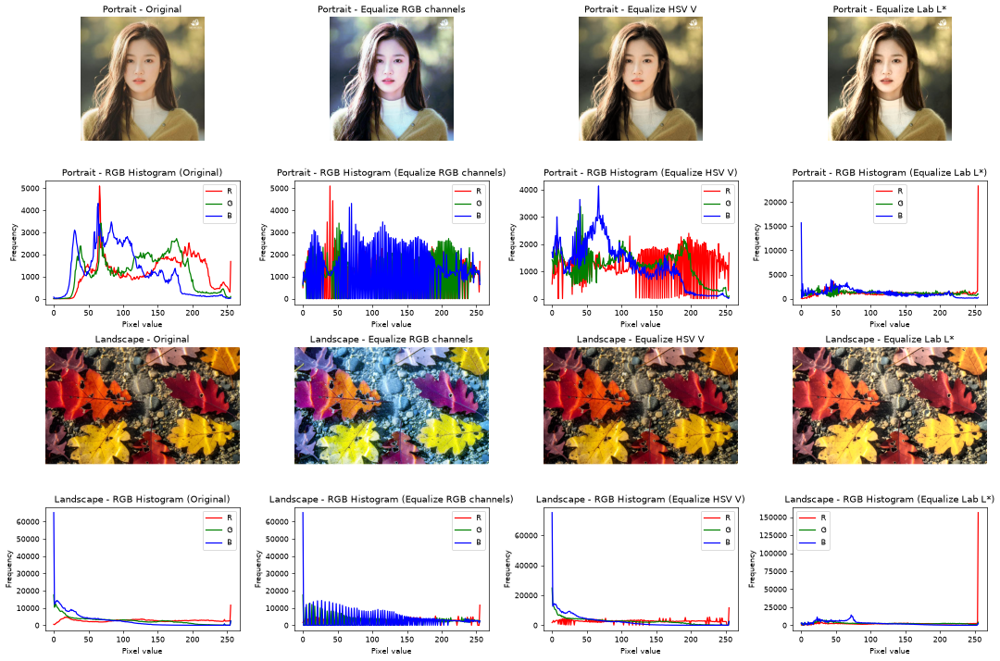

In [11]:
portrait = load_image("anh_chan_dung.jpg")
landscape = load_image("leaves.png")

comparison_images = [
    (portrait, "Portrait"),
    (landscape, "Landscape"),
]

fig, axes = plt.subplots(len(comparison_images) * 2, 4, figsize=(18, 12))
channel_colors = ["red", "green", "blue"]
channel_names = ["R", "G", "B"]

for row, (image, title) in enumerate(comparison_images):
    # Equalize t?ng k?nh RGB
    rgb_equalized = cv2.merge([
        cv2.equalizeHist(channel) for channel in cv2.split(image)
    ])

    # Equalize k?nh V trong HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hue, saturation, value = cv2.split(hsv)
    hsv_equalized = cv2.cvtColor(
        cv2.merge([hue, saturation, cv2.equalizeHist(value)]),
        cv2.COLOR_HSV2RGB,
    )

    # Equalize k?nh L* trong Lab
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    lightness, a_channel, b_channel = cv2.split(lab)
    lab_equalized = cv2.cvtColor(
        cv2.merge([cv2.equalizeHist(lightness), a_channel, b_channel]),
        cv2.COLOR_LAB2RGB,
    )

    results = [
        (image, "Original"),
        (rgb_equalized, "Equalize RGB channels"),
        (hsv_equalized, "Equalize HSV V"),
        (lab_equalized, "Equalize Lab L*"),
    ]

    image_row = row * 2
    histogram_row = image_row + 1
    for column, (result, method) in enumerate(results):
        axes[image_row, column].imshow(result)
        axes[image_row, column].set_title(f"{title} - {method}")
        axes[image_row, column].axis("off")

        for channel_index, (channel_name, color) in enumerate(
            zip(channel_names, channel_colors)
        ):
            histogram, _ = np.histogram(
                result[:, :, channel_index], bins=256, range=(0, 256)
            )
            axes[histogram_row, column].plot(
                np.arange(256), histogram, color=color, label=channel_name
            )

        axes[histogram_row, column].set_title(f"{title} - RGB Histogram ({method})")
        axes[histogram_row, column].set_xlabel("Pixel value")
        axes[histogram_row, column].set_ylabel("Frequency")
        axes[histogram_row, column].legend()

plt.tight_layout()
plt.show()


### Đánh giá — Ảnh chân dung và ảnh phong cảnh

Trong output, equalize riêng từng kênh RGB làm màu da chân dung nhợt và ngả hồng/xanh rõ hơn; ảnh lá phong cảnh cũng chuyển sang các sắc xanh/tím và vàng gắt. Histogram RGB của hai ảnh trải rộng sau xử lý, với các đỉnh ở vùng biên cho thấy một số giá trị bị dồn về mức rất tối hoặc rất sáng. Vì màu da nhạy với thay đổi màu, độ lệch trên ảnh chân dung đặc biệt dễ nhận ra.

Equalize trên **HSV-V** giữ sắc màu gần ảnh gốc nhất trong hai ảnh, dù độ tương phản tăng. Equalize trên **Lab-L*** cũng giữ màu tốt hơn cách RGB, nhưng làm vùng sáng mạnh hơn; điều này thấy rõ ở lá vàng và vùng sáng trên khuôn mặt.

Vì vậy, trong các kết quả này, equalize từng kênh RGB gây lệch màu nhiều nhất. HSV-V cho kết quả tự nhiên hơn; Lab-L* là lựa chọn khác khi muốn chỉnh độ sáng, nhưng cần để ý vùng sáng bị đẩy cao.

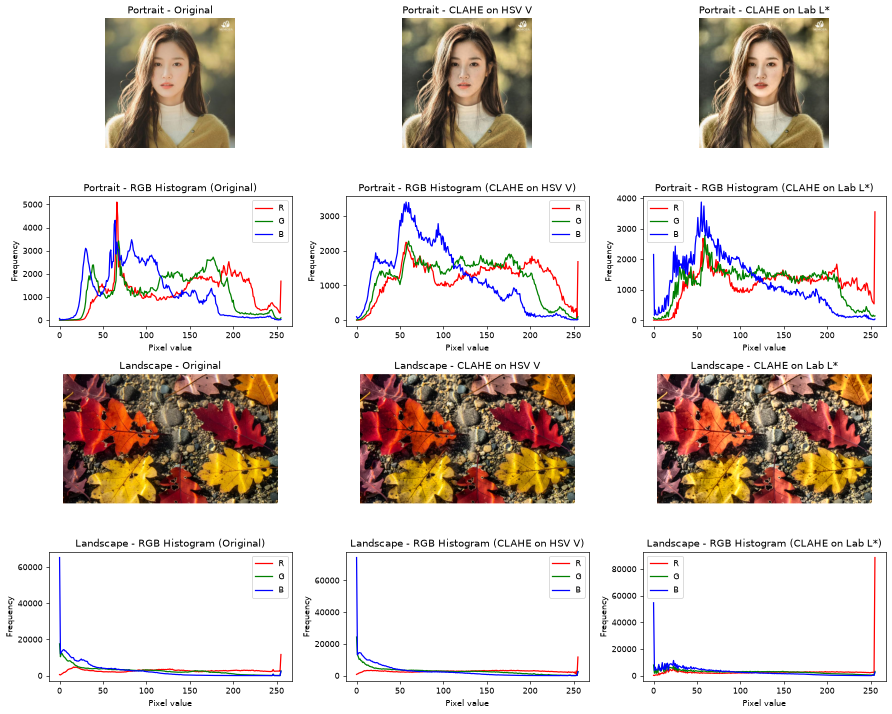

In [12]:
comparison_images = [
    (load_image("anh_chan_dung.jpg"), "Portrait"),
    (load_image("leaves.png"), "Landscape"),
]

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
fig, axes = plt.subplots(len(comparison_images) * 2, 3, figsize=(15, 12))
channel_colors = ["red", "green", "blue"]
channel_names = ["R", "G", "B"]

for row, (image, title) in enumerate(comparison_images):
    # CLAHE tr?n k?nh V c?a HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hue, saturation, value = cv2.split(hsv)
    value_clahe = clahe.apply(value)
    hsv_clahe = cv2.cvtColor(
        cv2.merge([hue, saturation, value_clahe]),
        cv2.COLOR_HSV2RGB,
    )

    # CLAHE tr?n k?nh L* c?a Lab
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    lightness, a_channel, b_channel = cv2.split(lab)
    lightness_clahe = clahe.apply(lightness)
    lab_clahe = cv2.cvtColor(
        cv2.merge([lightness_clahe, a_channel, b_channel]),
        cv2.COLOR_LAB2RGB,
    )

    results = [
        (image, "Original"),
        (hsv_clahe, "CLAHE on HSV V"),
        (lab_clahe, "CLAHE on Lab L*"),
    ]

    image_row = row * 2
    histogram_row = image_row + 1
    for column, (result, method) in enumerate(results):
        axes[image_row, column].imshow(result)
        axes[image_row, column].set_title(f"{title} - {method}")
        axes[image_row, column].axis("off")

        for channel_index, (channel_name, color) in enumerate(
            zip(channel_names, channel_colors)
        ):
            histogram, _ = np.histogram(
                result[:, :, channel_index], bins=256, range=(0, 256)
            )
            axes[histogram_row, column].plot(
                np.arange(256), histogram, color=color, label=channel_name
            )

        axes[histogram_row, column].set_title(f"{title} - RGB Histogram ({method})")
        axes[histogram_row, column].set_xlabel("Pixel value")
        axes[histogram_row, column].set_ylabel("Frequency")
        axes[histogram_row, column].legend()

plt.tight_layout()
plt.show()


### CLAHE — so sánh trực tiếp với cân bằng toàn cục

Equalization toàn cục dùng một phép ánh xạ cho toàn ảnh nên có thể làm vùng sáng bị gắt khi ảnh có ánh sáng không đều. CLAHE cân bằng từng ô lân cận và giới hạn độ khuếch đại histogram; vì vậy thường khôi phục chi tiết cục bộ tốt hơn, nhưng có thể làm nhiễu nổi rõ nếu `clipLimit` quá cao. Kết quả phụ thuộc ảnh và kích thước ô.

Ở hình so sánh cuối notebook, hãy đối chiếu ảnh gốc, equalization toàn cục và CLAHE trên cùng kênh độ sáng. Histogram được chuẩn hóa theo tổng pixel để so sánh được giữa ảnh khác kích thước. Chọn V khi ưu tiên sự đơn giản; chọn L* khi muốn thao tác trên độ sáng gần cảm nhận hơn. Cả hai vẫn có thể làm thay đổi cảm nhận màu sau chuyển đổi ngược.


# Lab05A — CIE XYZ và CIE Lab

Các thí nghiệm dưới đây bổ sung pipeline RGB → XYZ → Lab, kiểm tra với OpenCV, phân ngưỡng theo độ sáng và khoảng cách màu, cùng phân đoạn K-means trong XYZ/Lab. Kênh XYZ được hiển thị theo cùng khoảng giá trị của từng ảnh để thấy cấu trúc; đây là ảnh chuẩn hóa để quan sát, không phải màu hiển thị XYZ trực tiếp. Khi kiểm chứng XYZ, cả hai cách đều nhận RGB đã tuyến tính hóa theo sRGB; nếu đưa RGB gamma-encoded thẳng vào OpenCV thì phép đổi ma trận sẽ không còn cùng đầu vào với công thức CIE ở trên.

In [13]:
# Chuyển đổi sRGB -> XYZ tuyến tính -> CIE Lab với white point D65.
# OpenCV RGB2XYZ dùng thang uint8; chuẩn hóa kết quả về [0, 1] để đối chiếu.
D65 = np.array([0.95047, 1.0, 1.08883], dtype=np.float32)
RGB_TO_XYZ = np.array([
    [0.4124564, 0.3575761, 0.1804375],
    [0.2126729, 0.7151522, 0.0721750],
    [0.0193339, 0.1191920, 0.9503041],
], dtype=np.float32)

def rgb_to_xyz_float(image_rgb):
    srgb = image_rgb.astype(np.float32) / 255.0
    linear = np.where(srgb <= 0.04045, srgb / 12.92, ((srgb + 0.055) / 1.055) ** 2.4)
    return linear @ RGB_TO_XYZ.T

def xyz_to_lab_float(xyz):
    ratio = xyz / D65
    delta = 6 / 29
    f = np.where(ratio > delta ** 3, np.cbrt(np.maximum(ratio, 0)), ratio / (3 * delta ** 2) + 4 / 29)
    fx, fy, fz = np.moveaxis(f, -1, 0)
    return np.stack([116 * fy - 16, 500 * (fx - fy), 200 * (fy - fz)], axis=-1)

xyz_custom = rgb_to_xyz_float(img1)
lab_custom = xyz_to_lab_float(xyz_custom)
srgb_float = img1.astype(np.float32) / 255.0
linear_float = np.where(srgb_float <= 0.04045, srgb_float / 12.92, ((srgb_float + 0.055) / 1.055) ** 2.4)
xyz_cv = cv2.cvtColor(linear_float, cv2.COLOR_RGB2XYZ)
lab_cv = cv2.cvtColor(srgb_float, cv2.COLOR_RGB2LAB)

print(f"XYZ mean absolute difference vs OpenCV float32 (same linear input): {np.abs(xyz_custom - xyz_cv).mean():.6f}")
print(f"Lab mean absolute difference vs OpenCV float32: {np.abs(lab_custom - lab_cv).mean():.5f}")


XYZ mean absolute difference vs OpenCV float32 (same linear input): 0.000002
Lab mean absolute difference vs OpenCV float32: 0.07004


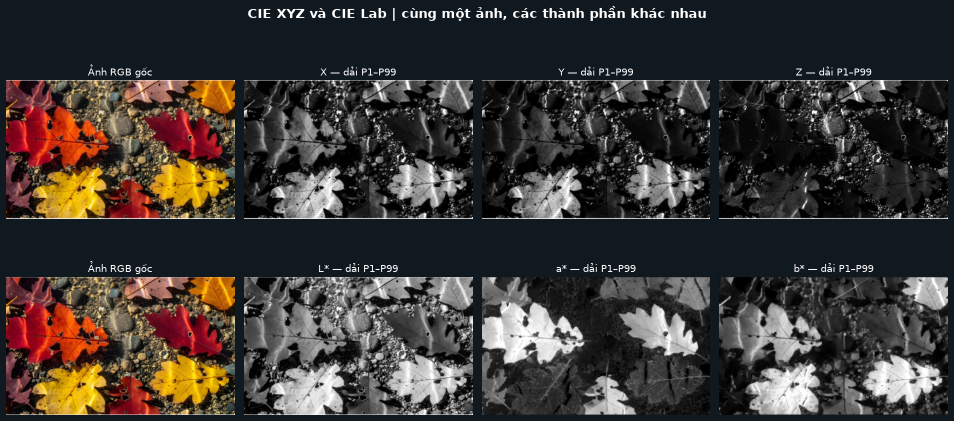

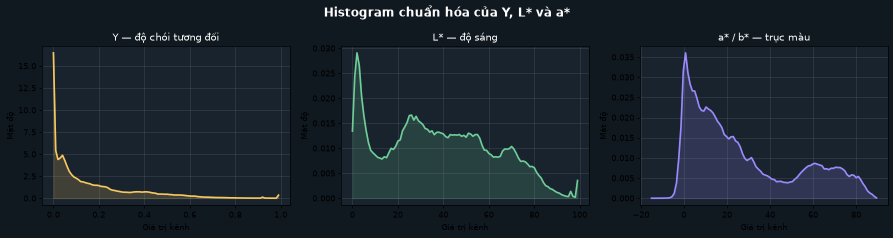

In [14]:
# So sánh cấu trúc các kênh XYZ và Lab trên cùng ảnh.
channel_sets = [(xyz_custom, ["X", "Y", "Z"]), (lab_custom, ["L*", "a*", "b*"])]
fig, axes = plt.subplots(2, 4, figsize=(16, 8), facecolor="#101820")
for row, (values, names) in enumerate(channel_sets):
    axes[row, 0].imshow(img1)
    axes[row, 0].set_title("Ảnh RGB gốc", color="white")
    for col, name in enumerate(names, start=1):
        channel = values[..., col - 1]
        lo, hi = np.percentile(channel, [1, 99])
        axes[row, col].imshow(channel, cmap="gray", vmin=lo, vmax=hi)
        axes[row, col].set_title(f"{name} — dải P1–P99", color="white")
    for ax in axes[row]:
        ax.axis("off")
        ax.set_facecolor("#101820")
fig.suptitle("CIE XYZ và CIE Lab | cùng một ảnh, các thành phần khác nhau", color="white", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), facecolor="#101820")
for ax, index, name, color in zip(axes, [1, 0, 2], ["Y — độ chói tương đối", "L* — độ sáng", "a* / b* — trục màu"], ["#f6c85f", "#6fcd98", "#9b8afb"]):
    channel = xyz_custom[..., index] if index == 1 else lab_custom[..., index]
    hist, bins = np.histogram(channel, bins=100, density=True)
    ax.plot(bins[:-1], hist, color=color, linewidth=2)
    ax.fill_between(bins[:-1], hist, color=color, alpha=.18)
    ax.set_title(name, color="white")
    ax.set_xlabel("Giá trị kênh")
    ax.set_ylabel("Mật độ")
    ax.grid(alpha=.2)
    ax.set_facecolor("#18232e")
fig.suptitle("Histogram chuẩn hóa của Y, L* và a*", color="white", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()


## So sánh phân ngưỡng: grayscale, XYZ-Y và khoảng cách màu Lab

Y và L* trả lời câu hỏi vùng nào sáng hơn; chúng không nhất thiết tách được hai vật thể khác màu nhưng có độ sáng tương tự. Phân ngưỡng theo ΔE so màu với một mẫu màu, nên có thể chịu được thay đổi độ sáng vừa phải hơn, nhưng phụ thuộc cách chọn màu mẫu và ngưỡng τ. Ở ví dụ này, màu xanh lá mục tiêu được lấy từ các pixel xanh có độ bão hòa cao trong ảnh lá; đây là quy tắc tự động đơn giản để minh họa, không phải nhãn chuẩn.

Otsu gray=95, Otsu Y=55; tỷ lệ pixel được chọn: gray=64.7%, Y=48.4%, Lab=27.1%


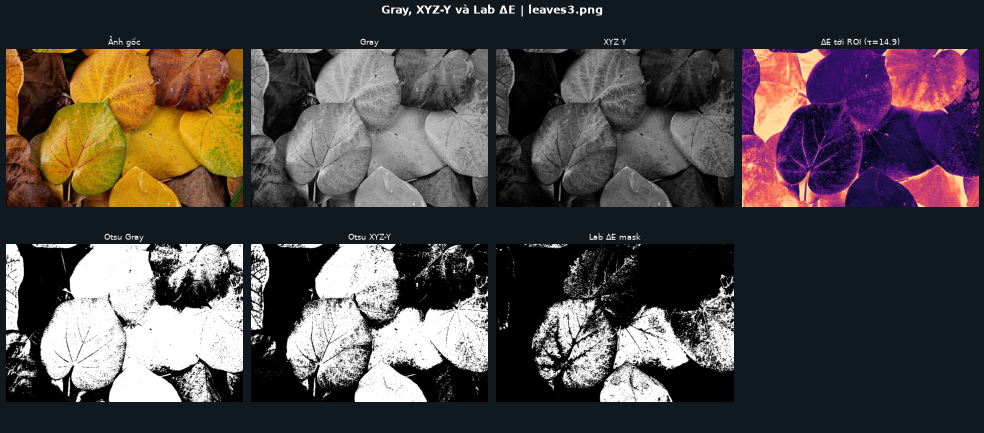

In [15]:
# Tạo ba mask trên ảnh lá: Otsu grayscale, Otsu trên Y và khoảng cách Lab tới xanh lá mẫu.
leaf = load_image("leaves3.png")
xyz_leaf = rgb_to_xyz_float(leaf)
lab_leaf = xyz_to_lab_float(xyz_leaf)
gray = cv2.cvtColor(leaf, cv2.COLOR_RGB2GRAY)
y_u8 = np.clip(xyz_leaf[..., 1] * 255, 0, 255).astype(np.uint8)
_, mask_gray = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, mask_y = cv2.threshold(y_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# ROI cố định 50x50 trong lá vàng-xanh làm màu mẫu để giảm nhiễu nền.
roi=lab_leaf[210:260,200:250]
target_lab=np.median(roi.reshape(-1,3),axis=0)
delta_e=np.linalg.norm(lab_leaf-target_lab,axis=2)
tau=float(np.percentile(delta_e[210:260,200:250],90))
mask_lab=(delta_e<=tau).astype(np.uint8)*255
fig,axes=plt.subplots(2,4,figsize=(18,8),facecolor="#101820")
items=[(leaf,"Ảnh gốc",None),(gray,"Gray", "gray"),(y_u8,"XYZ Y", "gray"),(delta_e,f"ΔE tới ROI (τ={tau:.1f})","magma"),
       (mask_gray,"Otsu Gray", "gray"),(mask_y,"Otsu XYZ-Y", "gray"),(mask_lab,"Lab ΔE mask", "gray")]
for ax,(image,title,cmap) in zip(axes.ravel(),items):
    ax.imshow(image,cmap=cmap); ax.set_title(title,color="white",fontsize=10); ax.axis("off")
axes.ravel()[-1].axis("off")
fig.suptitle("Gray, XYZ-Y và Lab ΔE | leaves3.png", color="white", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()
print(f"Otsu gray={cv2.threshold(gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)[0]:.0f}, "
      f"Otsu Y={cv2.threshold(y_u8,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)[0]:.0f}; "
      f"tỷ lệ pixel được chọn: gray={np.mean(mask_gray > 0):.1%}, Y={np.mean(mask_y > 0):.1%}, Lab={np.mean(mask_lab > 0):.1%}")


## Phân đoạn K-means: XYZ và Lab

K-means gom pixel theo khoảng cách Euclid tới tâm cụm. XYZ mô tả màu chuẩn hóa theo mô hình thị giác CIE; Lab có trục L* và trục màu a*, b* gần đều cảm nhận hơn. Số cụm K được giữ cố định để so sánh. Nhãn cụm được tô bằng màu trung bình RGB của pixel thành viên để giữ khả năng đọc như ảnh; màu nhãn không phải màu tâm XYZ/Lab chuyển ngược.


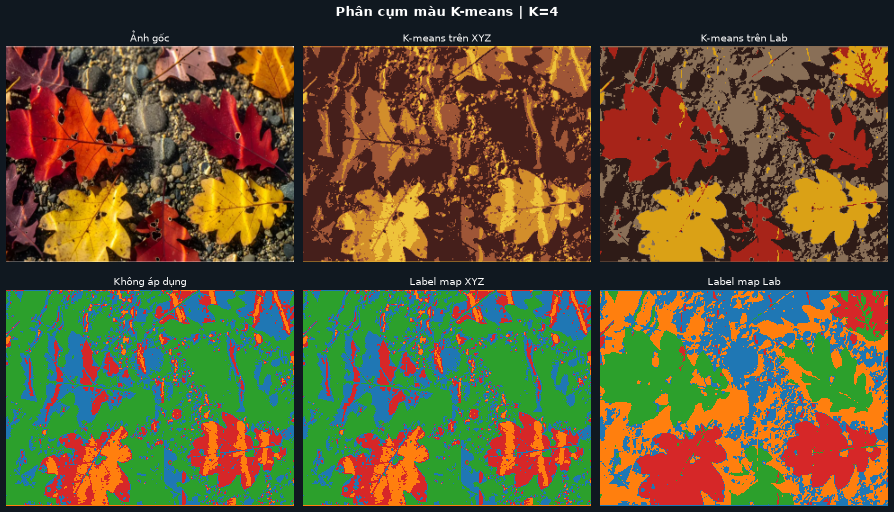

In [16]:
from sklearn.cluster import KMeans


def kmeans_labels(features, n_clusters=4, random_state=7):
    h, w, channels = features.shape
    pixels = features.reshape(-1, channels)
    model = KMeans(n_clusters=n_clusters, n_init=5, random_state=random_state)
    labels = model.fit_predict(pixels)
    return labels.reshape(h, w)


def mean_color_render(image, labels):
    output = np.zeros_like(image)
    for label in np.unique(labels):
        pixels = image[labels == label]
        output[labels == label] = np.mean(pixels, axis=0).astype(np.uint8)
    return output

# Giảm kích thước để chạy ổn định và hiển thị nhanh trong notebook.
small = cv2.resize(img1, (320, 240), interpolation=cv2.INTER_AREA)
small_xyz = rgb_to_xyz_float(small)
small_lab = xyz_to_lab_float(small_xyz)
labels_xyz = kmeans_labels(small_xyz, n_clusters=4)
labels_lab = kmeans_labels(small_lab, n_clusters=4)
render_xyz = mean_color_render(small, labels_xyz)
render_lab = mean_color_render(small, labels_lab)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), facecolor="#101820")
for ax, image, title in zip(axes[0], [small, render_xyz, render_lab], ["Ảnh gốc", "K-means trên XYZ", "K-means trên Lab"]):
    ax.imshow(image)
    ax.set_title(title, color="white")
    ax.axis("off")
for ax, labels, title in zip(axes[1], [labels_xyz, labels_xyz, labels_lab], ["Không áp dụng", "Label map XYZ", "Label map Lab"]):
    ax.imshow(labels, cmap="tab10", interpolation="nearest", vmin=0, vmax=9)
    ax.set_title(title, color="white")
    ax.axis("off")
axes[1, 0].axis("off")
fig.suptitle("Phân cụm màu K-means | K=4", color="white", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()


## Kết luận đối chiếu hai bài thực hành

- Histogram RGB và Hue mô tả phân bố màu, nhưng chỉ Hue không mang thông tin độ sáng; ảnh ít bão hòa có thể có Hue kém ổn định.
- Equalization riêng từng kênh RGB thường làm lệch màu. HSV-V và Lab-L* thay đổi chủ yếu thành phần độ sáng; CLAHE tăng tương phản cục bộ và hữu ích hơn khi chiếu sáng không đều, nhưng có thể làm nhiễu nổi rõ.
- XYZ-Y phù hợp cho ngưỡng sáng/tối. ΔE Lab phù hợp hơn khi cần chọn một màu mục tiêu, còn K-means Lab thường cho cụm màu gần cảm nhận hơn. Không có phương pháp nào luôn tốt nhất: cần xem mask/label map trên ảnh cụ thể và chọn ngưỡng hoặc K theo mục tiêu.
- Chuyển đổi custom XYZ/Lab có thể lệch nhẹ so với OpenCV do mã hóa và lượng tử hóa Lab 8-bit; phép so sánh ở trên quy đổi Lab OpenCV về đơn vị gần L*, a*, b* trước khi tính sai số.


# Lab05A — hoàn thành các yêu cầu phân tích và thí nghiệm

Các phần sau trả lời lần lượt câu hỏi/bài tập trong PDF, dùng kết quả sinh ra từ ảnh của lab. Ảnh thật và ảnh tổng hợp được trình bày cạnh nhau để thấy rõ giới hạn của từng hệ màu. Ngưỡng và hạt giống được ghi rõ trong từng cell để có thể lặp lại hoặc điều chỉnh khi chạy trên ảnh khác.

## 6.5 — Đọc các kênh XYZ và Lab; ảnh hưởng của white point

**Trả lời câu hỏi.** X, Y, Z là các thành phần tristimulus được tạo bởi các hàm phối màu CIE; Y gần với độ chói tương đối, còn X và Z mang thông tin phổ màu bổ sung. Vì vậy cùng một cảnh có thể nổi rõ cấu trúc khác nhau trong từng kênh. Trong Lab, L* biểu diễn độ sáng, a* là trục xanh lục (âm) ↔ đỏ (dương), b* là trục xanh lam (âm) ↔ vàng (dương).

Điểm trắng là mốc chuẩn hóa XYZ trước khi tính Lab. Đổi D65 thành D50 mà không thích nghi màu (chromatic adaptation) làm thay đổi L*, a*, b* và do đó cả ΔE. Trên ảnh này ΔEab trung bình=6.13, trung vị=6.09, P95=11.26. Khi muốn biểu diễn cùng màu dưới nguồn sáng khác, cần thực hiện thích nghi điểm trắng; thay riêng ba hằng số là thí nghiệm độ nhạy, không phải cân bằng trắng hoàn chỉnh. Cell kế tiếp đo mức thay đổi trên dữ liệu `leaves.png`.

D65→D50 without adaptation: mean ΔEab=6.13, median=6.09, P95=11.26


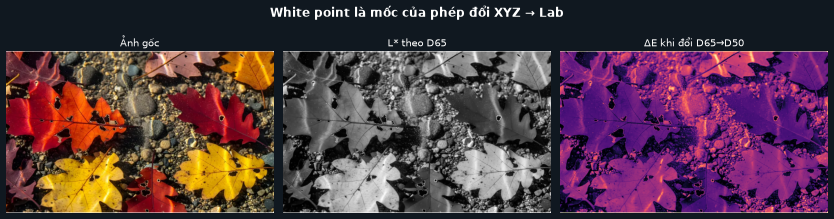

In [17]:
# Độ nhạy Lab với white point: D65 so với D50 (không chromatic adaptation).
D50 = np.array([0.96422, 1.0, 0.82521], dtype=np.float32)
def xyz_to_lab_with_white(xyz, white):
    ratio = xyz / np.asarray(white, dtype=np.float32)
    delta = 6 / 29
    f = np.where(ratio > delta**3, np.cbrt(np.maximum(ratio, 0)), ratio/(3*delta**2)+4/29)
    fx, fy, fz = np.moveaxis(f, -1, 0)
    return np.stack([116*fy-16, 500*(fx-fy), 200*(fy-fz)], axis=-1)
lab_d50 = xyz_to_lab_with_white(xyz_custom, D50)
delta_white = np.linalg.norm(lab_custom-lab_d50, axis=2)
print(f"D65→D50 without adaptation: mean ΔEab={delta_white.mean():.2f}, median={np.median(delta_white):.2f}, P95={np.percentile(delta_white,95):.2f}")
fig, axes = plt.subplots(1,3,figsize=(14,4),facecolor="#101820")
for ax, image, title, cmap in [(axes[0],img1,"Ảnh gốc",None),(axes[1],lab_custom[...,0],"L* theo D65","gray"),(axes[2],delta_white,"ΔE khi đổi D65→D50","magma")]:
    ax.imshow(image,cmap=cmap); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle("White point là mốc của phép đổi XYZ → Lab",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()


## 6.6 — So sánh Lab tự cài đặt, OpenCV và histogram Y/L*/a*/b*

Phép chuyển đổi tự cài đặt dùng ma trận sRGB→XYZ với bước tuyến tính hóa sRGB và điểm trắng D65. OpenCV có các đường chuyển đổi riêng; so sánh định lượng chỉ có ý nghĩa khi cùng quy ước đầu vào, thang đo và white point. Sai số trung bình được in ở cell chuyển đổi phía trên; sai khác nhỏ còn lại đến từ hằng số ma trận, xấp xỉ số học và quy ước chuyển đổi của thư viện.

Về histogram: Y và L* thường có phân bố một đỉnh hoặc nhiều đỉnh theo vùng tối/sáng trong ảnh; a* và b* tập trung quanh vùng màu trung tính nếu ảnh ít bão hòa, còn ảnh lá mùa thu phân bố lệch theo màu vàng/đỏ. Histogram là phân bố toàn cục, không cho biết vị trí các pixel; cần đọc cùng bản đồ kênh ở hình trên.

Gốc: mean L*=38.07; median |ΔH| vs original (S>40)=0.0 OpenCV hue units
Bóng (×0.52): mean L*=19.25; median |ΔH| vs original (S>40)=0.0 OpenCV hue units
Sáng (×1.18): mean L*=43.97; median |ΔH| vs original (S>40)=0.0 OpenCV hue units


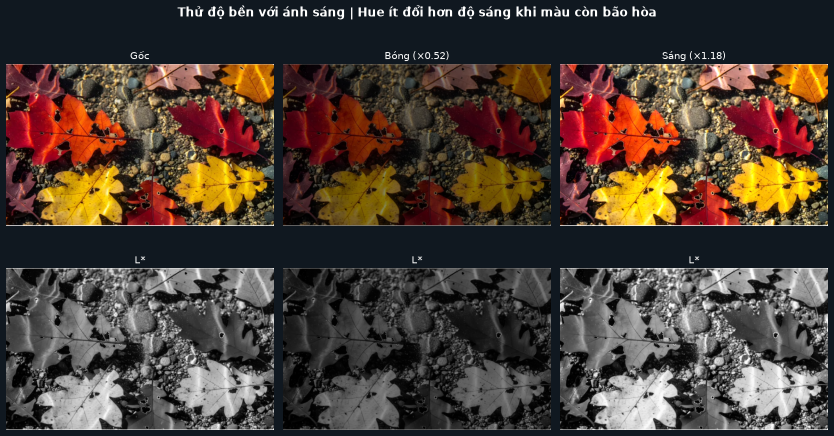

In [18]:
# Định lượng thay đổi dưới biến thiên chiếu sáng tổng hợp; Hue chỉ so ở pixel đủ bão hòa.
base = img1.astype(np.float32)/255
shadow = np.clip(base*0.52,0,1)
bright = np.clip(base*1.18,0,1)
variants=[("Gốc",img1),("Bóng (×0.52)",(shadow*255).astype(np.uint8)),("Sáng (×1.18)",(bright*255).astype(np.uint8))]
fig, axes=plt.subplots(2,3,figsize=(14,8),facecolor="#101820")
for j,(name,im) in enumerate(variants):
    hsv=cv2.cvtColor(im,cv2.COLOR_RGB2HSV); xyz=rgb_to_xyz_float(im); lab=xyz_to_lab_float(xyz)
    axes[0,j].imshow(im); axes[0,j].set_title(name,color="white"); axes[0,j].axis("off")
    axes[1,j].imshow(lab[...,0],cmap="gray",vmin=0,vmax=100); axes[1,j].set_title("L*",color="white"); axes[1,j].axis("off")
    if j==0: ref_h,ref_s=hsv[...,0],hsv[...,1]
    valid=(hsv[...,1]>40)&(ref_s>40)
    dh=np.minimum(np.abs(hsv[...,0].astype(float)-ref_h),180-np.abs(hsv[...,0].astype(float)-ref_h))
    print(f"{name}: mean L*={lab[...,0].mean():.2f}; median |ΔH| vs original (S>40)={np.median(dh[valid]):.1f} OpenCV hue units")
fig.suptitle("Thử độ bền với ánh sáng | Hue ít đổi hơn độ sáng khi màu còn bão hòa",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()


### Nhận xét 6.6.2 — Kênh nào ổn định hơn khi đổi ánh sáng?

Trong phép thử nhân cường độ RGB, mean L* giảm từ 38.07 xuống 19.25 khi nhân sáng 0.52 và tăng lên 43.97 khi nhân 1.18; median |ΔH|=0.0 trên pixel S>40. Độ sáng thay đổi, Hue ổn định trong phép biến đổi đồng nhất. Hue không đáng tin ở vùng gần xám vì khi S≈0, góc màu không xác định tốt. Đây là phép thử chiếu sáng đồng đều có kiểm soát; bóng đổ thực tế còn có phản xạ, vật liệu và nhiễu nên cần đánh giá riêng.

## 7.11–7.12 — Otsu trên kênh, ngưỡng màu mẫu và chọn mẫu bằng chuột

Hình dưới áp dụng Otsu trên R, G, B, S, V, L* trên ảnh lá mùa thu; các mask nhị phân được đặt cạnh nhau. Otsu tối ưu tách hai lớp theo phương sai trong histogram một chiều, nhưng không biết lớp nào là mục tiêu. Vì vậy chất lượng mask phải được đọc theo bài toán, không chỉ theo con số ngưỡng.

Hàm `pick_lab_mask` cho phép click một điểm trên ảnh để lấy màu mục tiêu Lab và sinh mask theo ΔE; khi chạy cell, click vào vật thể mẫu rồi đóng cửa sổ. Trong phần chạy tự động bên dưới, dùng ROI 50×50 pixel nằm trong chiếc lá vàng-xanh của `leaves3.png` làm mẫu cố định để notebook chạy hoàn toàn không tương tác.

Otsu threshold / tỷ lệ pixel trắng: {'R': (130.0, 48.2), 'G': (88.0, 38.3), 'B': (56.0, 27.9), 'S': (159.0, 56.4), 'V': (130.0, 48.3), 'L*': (101.0, 45.8)}


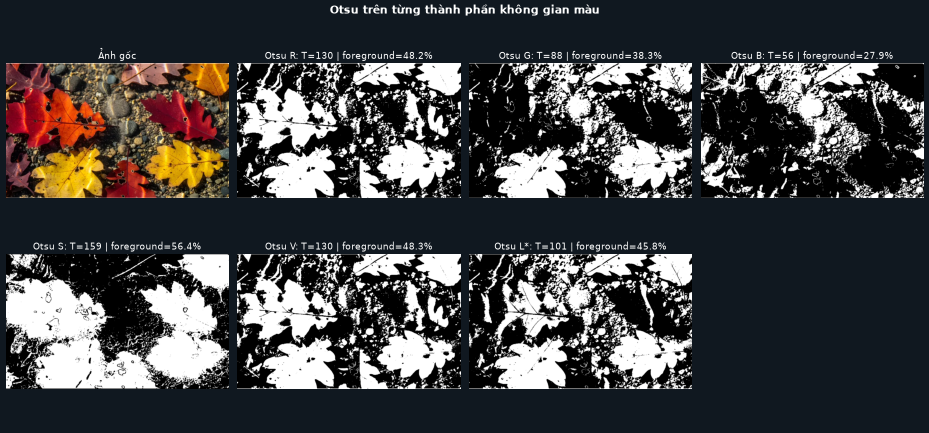

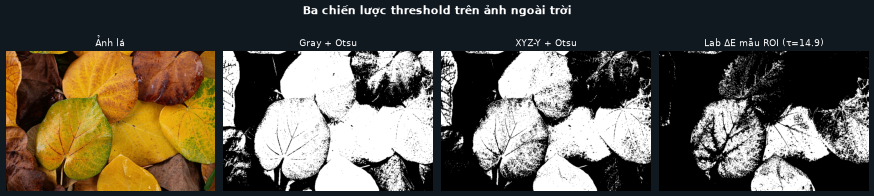

In [19]:
# Otsu trên R,G,B,S,V,L*; visualize cùng ảnh và mask.
otsu_channels={"R":img1[...,0],"G":img1[...,1],"B":img1[...,2],"S":hsv1[...,1],"V":hsv1[...,2],"L*":cv2.cvtColor(img1,cv2.COLOR_RGB2LAB)[...,0]}
fig,axes=plt.subplots(2,4,figsize=(17,8),facecolor="#101820")
axes[0,0].imshow(img1); axes[0,0].set_title("Ảnh gốc",color="white"); axes[0,0].axis("off")
otsu_stats={}
for ax,(name,ch) in zip(axes.ravel()[1:],otsu_channels.items()):
    threshold,mask=cv2.threshold(ch,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    otsu_stats[name]=(threshold,float(np.mean(mask>0)))
    ax.imshow(mask,cmap="gray"); ax.set_title(f"Otsu {name}: T={threshold:.0f} | foreground={np.mean(mask>0):.1%}",color="white"); ax.axis("off")
axes.ravel()[-1].axis("off")
fig.suptitle("Otsu trên từng thành phần không gian màu",color="white",fontsize=15,fontweight="bold"); fig.tight_layout(); plt.show()
print("Otsu threshold / tỷ lệ pixel trắng:", {k:(round(v[0],1),round(v[1]*100,1)) for k,v in otsu_stats.items()})

def pick_lab_mask(image_rgb,tau=18):
    fig,ax=plt.subplots(); ax.imshow(image_rgb); ax.set_title("Click pixel màu mẫu, sau đó đóng cửa sổ")
    point=plt.ginput(1,timeout=-1); plt.close(fig)
    if not point: raise ValueError("Chưa chọn pixel màu mẫu")
    x,y=np.round(point[0]).astype(int); lab=cv2.cvtColor(image_rgb,cv2.COLOR_RGB2LAB).astype(np.float32); lab[...,0]*=100/255; lab[...,1:]-=128
    dist=np.linalg.norm(lab-lab[y,x],axis=2)
    return (dist<=tau).astype(np.uint8)*255,(x,y),lab[y,x]

# Mẫu ROI xanh trong ảnh lá. Thay ROI hoặc gọi pick_lab_mask(img1) để chọn bằng chuột.
roi=lab_leaf[210:260,200:250]
target_lab_auto=np.median(roi.reshape(-1,3),axis=0)
dist_roi=np.linalg.norm(lab_leaf-target_lab_auto,axis=2)
tau_roi=float(np.percentile(dist_roi[210:260,200:250],90))
mask_delta=(dist_roi<=tau_roi).astype(np.uint8)*255
# Chỉ số xanh lá chuẩn hóa, kèm Otsu làm baseline nhiều kênh.
r,g,b=[leaf[...,i].astype(np.float32) for i in range(3)]
exg=2*g-r-b; exg_u8=cv2.normalize(exg,None,0,255,cv2.NORM_MINMAX).astype(np.uint8)
t_exg,mask_exg=cv2.threshold(exg_u8,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
fig,axes=plt.subplots(1,4,figsize=(16,4),facecolor="#101820")
for ax,image,title,cmap in zip(axes,[leaf,mask_gray,mask_y,mask_delta],["Ảnh lá","Gray + Otsu","XYZ-Y + Otsu",f"Lab ΔE mẫu ROI (τ={tau_roi:.1f})"],[None,"gray","gray","gray"]):
    ax.imshow(image,cmap=cmap); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle("Ba chiến lược threshold trên ảnh ngoài trời",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()


### Trả lời 7.11–7.13 — So sánh threshold và pipeline cây xanh

- Ngưỡng Y phù hợp khi đối tượng và nền khác nhau chủ yếu về độ sáng. Nó không đủ khi hai màu khác nhau nhưng độ sáng tương tự, hoặc khi bóng đổ làm Y của cùng đối tượng trải rộng.
- ΔE Lab so cả L*, a*, b* với một màu mẫu nên xử lý được màu khác nhau nhưng gần sáng; kết quả vẫn phụ thuộc mẫu, τ, ánh sáng và nền tương tự màu.
- Nếu cùng màu có nhiều mức sáng, ΔE Lab thường hợp lý hơn Y; tăng τ vừa đủ bao phủ biến thiên sáng nhưng phải kiểm tra nền bị lẫn.
- Trên `leaves3.png`, Gray Otsu chọn 64.7%, XYZ-Y chọn 48.4%, còn ΔE tới ROI mẫu (τ=14.9) chọn 27.1%. Đây là foreground ratio, không phải accuracy vì thiếu ground truth.
- Opening bỏ chấm nhỏ, closing lấp lỗ/nối vùng; kernel nên nhỏ hơn chi tiết lá. Cell sau đo số components trước/sau morphology. Hàm click-mẫu có sẵn để đổi target; cell chạy tự động dùng ROI cố định.

## 7.12.3 — Morphology và threshold màu lá: kết quả trước/sau làm sạch

Opening = erosion rồi dilation để bỏ thành phần nhỏ; closing = dilation rồi erosion để nối khe/lấp lỗ nhỏ. Cell đo số thành phần liên thông trước/sau và hiển thị mask cùng overlay. Đây là ví dụ định tính; kích thước kernel 5×5 được giữ cố định để tái lập.

raw: foreground=27.1%, components=1743
opening: foreground=15.3%, components=159
opening+closing: foreground=16.8%, components=68


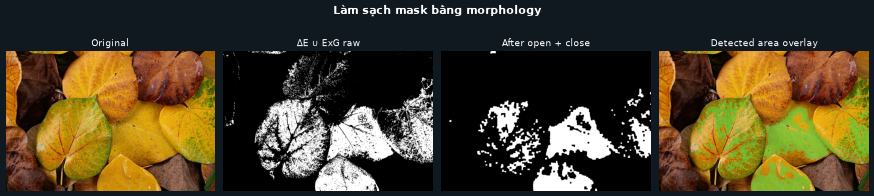

In [20]:
kernel=np.ones((5,5),np.uint8)
mask_green_raw=mask_delta.copy()
mask_green_open=cv2.morphologyEx(mask_green_raw,cv2.MORPH_OPEN,kernel)
mask_green_clean=cv2.morphologyEx(mask_green_open,cv2.MORPH_CLOSE,kernel)
def component_count(mask):
    return cv2.connectedComponents((mask>0).astype(np.uint8))[0]-1
for name,mask in [("raw",mask_green_raw),("opening",mask_green_open),("opening+closing",mask_green_clean)]: print(f"{name}: foreground={np.mean(mask>0):.1%}, components={component_count(mask)}")
overlay=leaf.copy(); overlay[mask_green_clean>0]=(0.6*overlay[mask_green_clean>0]+0.4*np.array([30,240,100])).astype(np.uint8)
fig,axes=plt.subplots(1,4,figsize=(16,4),facecolor="#101820")
for ax,image,title in zip(axes,[leaf,mask_green_raw,mask_green_clean,overlay],["Original","ΔE raw","After open + close","Detected area overlay"]): ax.imshow(image,cmap="gray" if image.ndim==2 else None); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle("Làm sạch mask bằng morphology",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()


## 8.9–8.11 — K-means RGB/HSV/XYZ/Lab và tọa độ không gian

K-means trên màu chỉ gom các pixel gần nhau về màu, nên cùng một màu xuất hiện ở nhiều vị trí có thể nằm cùng cụm. Thêm x,y vào vector đặc trưng phạt các pixel ở xa nhau; hệ số λ điều khiển mức ưu tiên tính liên tục không gian. Chuẩn hóa mỗi kênh trước khi ghép vì đơn vị XYZ, Lab, x,y khác nhau.

Hình so sánh dùng cùng ảnh và K. Các màu hiển thị là trung bình RGB của từng cluster; label map dùng cùng palette. Phần tiếp theo thử K=2,3,4,5 trên ảnh tablets nhiều màu để thấy tăng K chia nhỏ cụm như thế nào.

Số cụm thực tế theo K: {2: 2, 3: 3, 4: 4, 5: 5}


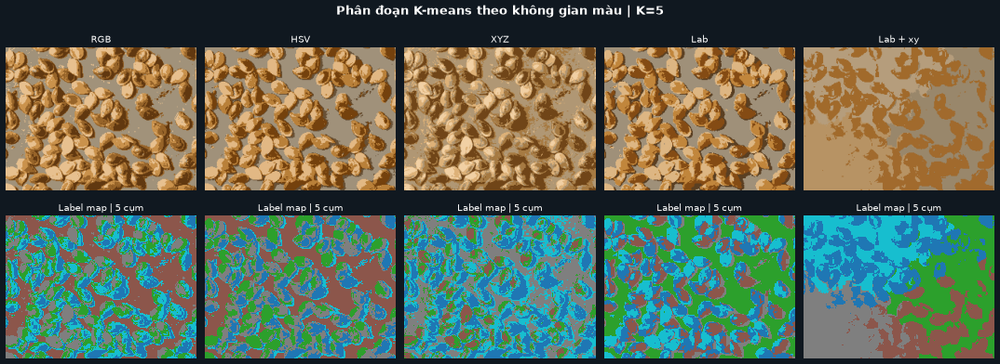

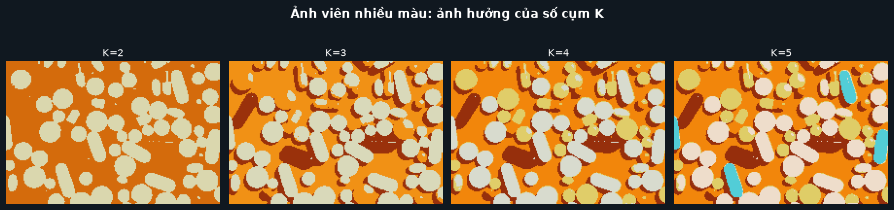

In [21]:
# K-means trên RGB, HSV, XYZ, Lab và Lab+(x,y), cùng K=5, ảnh seed2.
from sklearn.cluster import KMeans
small_rgb=cv2.resize(load_image("seed2.png"),(260,195),interpolation=cv2.INTER_AREA)
small_hsv=cv2.cvtColor(small_rgb,cv2.COLOR_RGB2HSV).astype(np.float32); small_hsv[...,0]*=2
small_xyz=rgb_to_xyz_float(small_rgb); small_lab=xyz_to_lab_float(small_xyz)
def norm_features(a):
    a=a.astype(np.float32); lo=a.reshape(-1,a.shape[-1]).min(axis=0); hi=a.reshape(-1,a.shape[-1]).max(axis=0)
    return (a-lo)/(hi-lo+1e-6)
def cluster_features(a,k=5):
    h,w,c=a.shape; z=norm_features(a).reshape(-1,c)
    return KMeans(n_clusters=k,n_init=5,random_state=11).fit_predict(z).reshape(h,w)
def render_labels(image,labels):
    out=np.zeros_like(image)
    for k in np.unique(labels): out[labels==k]=np.mean(image[labels==k],axis=0).astype(np.uint8)
    return out
feature_maps={"RGB":small_rgb.astype(np.float32),"HSV":small_hsv,"XYZ":small_xyz,"Lab":small_lab}
cluster_results={name:cluster_features(feat,5) for name,feat in feature_maps.items()}
# x,y có trọng số λ sau chuẩn hóa, cho yếu tố spatial regularization.
yy,xx=np.mgrid[0:small_rgb.shape[0],0:small_rgb.shape[1]]
xy=np.stack([xx/xx.max(),yy/yy.max()],axis=-1).astype(np.float32)*0.18
cluster_results["Lab + xy"]=cluster_features(np.concatenate([norm_features(small_lab),xy],axis=-1),5)
fig,axes=plt.subplots(2,5,figsize=(18,7),facecolor="#101820")
for j,(name,labels) in enumerate(cluster_results.items()):
    axes[0,j].imshow(render_labels(small_rgb,labels)); axes[0,j].set_title(name,color="white"); axes[0,j].axis("off")
    axes[1,j].imshow(labels,cmap="tab10",interpolation="nearest"); axes[1,j].set_title(f"Label map | {len(np.unique(labels))} cụm",color="white"); axes[1,j].axis("off")
fig.suptitle("Phân đoạn K-means theo không gian màu | K=5",color="white",fontsize=15,fontweight="bold"); fig.tight_layout(); plt.show()
# So sánh K=2..5 trên tablets4.png, mô tả bằng số cluster và inertia.
fruit=cv2.resize(load_image("tablets4.png"),(220,147),interpolation=cv2.INTER_AREA); fruit_lab=xyz_to_lab_float(rgb_to_xyz_float(fruit)); k_results={}
fig,axes=plt.subplots(1,4,figsize=(15,4),facecolor="#101820")
for ax,k in zip(axes,[2,3,4,5]):
    labels=cluster_features(fruit_lab,k); k_results[k]=len(np.unique(labels)); ax.imshow(render_labels(fruit,labels)); ax.set_title(f"K={k}",color="white"); ax.axis("off")
fig.suptitle("Ảnh viên nhiều màu: ảnh hưởng của số cụm K",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
print("Số cụm thực tế theo K:",k_results)


### Trả lời 8.9–8.11 — Chọn không gian và K

- Lab phù hợp hơn RGB khi khoảng cách màu cảm nhận quan trọng; RGB tiện tính nhưng khoảng cách Euclid không đồng đều theo cảm nhận. XYZ hữu ích khi cần hệ chuẩn và tách Y, song khoảng cách Euclid XYZ không tối ưu cảm nhận. HSV trực quan cho màu nhưng Hue là đại lượng chu kỳ và kém ổn định ở vùng ít bão hòa.
- Tọa độ x,y khuyến khích vùng cụm liền mạch, giảm việc một nhãn xuất hiện rải rác toàn ảnh; λ lớn quá có thể bỏ qua các vật thể cùng màu nằm xa nhau.
- Với tablets nhiều màu, K nhỏ gộp màu gần nhau và K lớn tách thêm biến thiên sáng/bóng. Chọn K theo số nhóm màu có ý nghĩa cần trình bày và mức chi tiết mong muốn, không chỉ theo K lớn nhất.
- Pipeline nền phức tạp nên chọn đặc trưng Lab hoặc Lab+xy, K vừa đủ, lấy cluster mục tiêu theo màu trung bình/ROI, rồi opening/closing và giữ thành phần liên thông phù hợp. Label K-means không tự biết cluster nào là đối tượng; bước chọn cluster là cần thiết.

## 9–10.2 — Bộ ảnh synthetic giải thích failure modes

Tạo bốn ảnh tổng hợp có hình chữ nhật làm vùng mục tiêu: (1) biên isoluminant có cùng mức xám, (2) texture đổi sắc nhưng gần cùng Y, (3) màu vật thể dưới gradient chiếu sáng, (4) hình ẩn có L* gần nhau nhưng khác a*,b*. Trước khi chạy dự đoán: gray/Y sẽ bỏ biên ở (1)/(2); khoảng cách RGB cố định sẽ nhạy với gradient ở (3); L* edge sẽ bỏ hình ở (4), còn Lab chroma edge sẽ giữ nó.

Các panels dưới so sánh gray, Y và Lab color distance/gradient. Đây là thí nghiệm thiết kế có kiểm soát, không đại diện mọi ảnh tự nhiên; giá trị nằm ở việc cô lập một nguyên nhân thất bại mỗi lần.

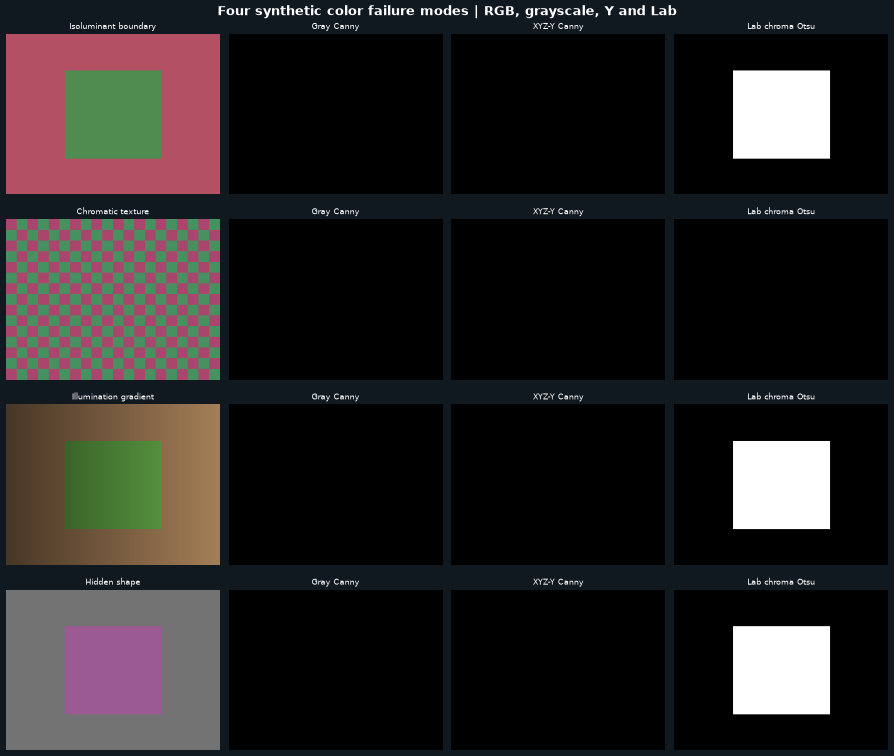

In [22]:
# Synthetic failure modes: ảnh được tạo trong không gian RGB, rồi pipeline chạy độc lập.
H,W=180,240; yy,xx=np.mgrid[0:H,0:W]; region=(xx>65)&(xx<175)&(yy>40)&(yy<140)
def make_pair(bg_rgb,fg_rgb):
    im=np.empty((H,W,3),np.uint8); im[:]=bg_rgb; im[region]=fg_rgb; return im
# Isoluminant dưới grayscale OpenCV (xấp xỉ): hai màu cùng Y_gray.
syn_iso=make_pair([180,80,100],[80,140,80])
# Chromatic texture: hai màu thay đổi theo ô checker, chọn gần cùng độ chói tuyến tính.
syn_texture=np.empty((H,W,3),np.uint8); checker=((xx//12+yy//12)%2)==0
syn_texture[:]=[110,110,110]; syn_texture[checker]=[170,70,110]; syn_texture[~checker]=[70,145,95]
# Illumination gradient nhân màu mục tiêu và nền theo cùng trường chiếu sáng.
illum=np.clip(0.48+0.62*xx/(W-1),0.35,1.1)[...,None]
syn_illum=np.clip(make_pair([150,115,80],[90,155,65]).astype(float)*illum,0,255).astype(np.uint8)
# Hidden shape: mức xám gần nhau nhưng sắc xanh/tím khác biệt rõ.
syn_hidden=make_pair([115,115,115],[155,90,145])
synthetic=[("Isoluminant boundary",syn_iso),("Chromatic texture",syn_texture),("Illumination gradient",syn_illum),("Hidden shape",syn_hidden)]
fig,axes=plt.subplots(4,4,figsize=(15,13),facecolor="#101820")
for row,(name,im) in enumerate(synthetic):
    gray_s=cv2.cvtColor(im,cv2.COLOR_RGB2GRAY)
    xyz_s=rgb_to_xyz_float(im); lab_s=xyz_to_lab_float(xyz_s)
    grad_gray=cv2.Canny(gray_s,40,100)
    grad_y=cv2.Canny(np.clip(xyz_s[...,1]*255,0,255).astype(np.uint8),40,100)
    chroma=np.sqrt((lab_s[...,1]-np.median(lab_s[...,1]))**2+(lab_s[...,2]-np.median(lab_s[...,2]))**2)
    _,mask_lab_s=cv2.threshold(cv2.normalize(chroma,None,0,255,cv2.NORM_MINMAX).astype(np.uint8),0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    for ax,imv,title,cmap in zip(axes[row],[im,grad_gray,grad_y,mask_lab_s],[name,"Gray Canny","XYZ-Y Canny","Lab chroma Otsu"],[None,"gray","gray","gray"]):
        ax.imshow(imv,cmap=cmap); ax.set_title(title,color="white",fontsize=9); ax.axis("off")
fig.suptitle("Four synthetic color failure modes | RGB, grayscale, Y and Lab",color="white",fontsize=15,fontweight="bold"); fig.tight_layout(); plt.show()


### Kết quả synthetic và giải thích

- **Isoluminant boundary:** gray/Y Canny yếu hoặc bỏ sót đường bao nếu hai màu có độ sáng tương đương; khác biệt màu vẫn hiện trên ảnh RGB và bản đồ Lab chroma.
- **Chromatic texture:** các ô màu đổi liên tục nhưng có độ chói gần nhau, nên Y không biểu diễn đầy đủ texture; gray có thể còn gợn do chuyển RGB→gray không hoàn toàn tương đương Y.
- **Illumination gradient:** ngưỡng khoảng cách màu RGB cố định dễ bỏ phần tối của cùng vật thể vì RGB thay đổi theo chiếu sáng. Màu mẫu Lab/ΔE thường bền hơn với biến đổi độ sáng vừa phải nhưng không bất biến hoàn toàn.
- **Hidden shape:** L*/gray/Y chủ yếu đo sáng nên khó thấy hình khi L* gần nhau; a*, b* và color gradient thể hiện đường bao.

Kết quả xác nhận dự đoán định tính. Với ảnh tổng hợp, ngưỡng Otsu trên chroma có thể chọn cả nền nếu nền cũng có màu; do đó nên kết hợp khoảng cách đến màu mẫu hoặc giới hạn vùng quan tâm thay vì coi một mask duy nhất là chân lý.


## 10.1 — Bài tổng hợp: threshold và ít nhất bốn cách dò biên

Dùng `leaves.png` làm ảnh thật có cây/lá, vùng bóng sáng khác nhau và nhiều biên màu yếu về độ sáng. So sánh: Canny trên gray; Canny trên XYZ-Y; Canny trên HSV-S; hợp nhất Canny trên a*,b* của Lab; và gradient vector màu Lab. Hình overlay cho thấy vị trí cạnh mà từng cách giữ lại. Các ngưỡng Canny cố định được áp dụng nhất quán để so phương pháp; cần tinh chỉnh theo ảnh ở ứng dụng thực tế.

Edge density: {'Gray Canny': 21.9, 'XYZ-Y Canny': 17.67, 'HSV-S Canny': 26.77, 'Lab a*/b* union': 13.42, 'Lab vector gradient': 27.08}


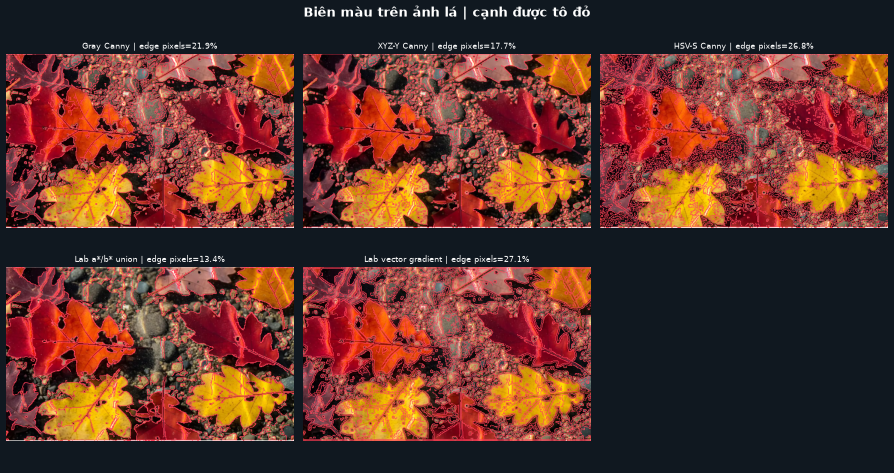

In [23]:
# Color-aware edges: gray, XYZ-Y, HSV-S, Lab a/b union và vector gradient Lab.
edge_img=cv2.resize(img1,(480,290),interpolation=cv2.INTER_AREA)
gray_e=cv2.cvtColor(edge_img,cv2.COLOR_RGB2GRAY)
xyz_e=rgb_to_xyz_float(edge_img); lab_e=xyz_to_lab_float(xyz_e); hsv_e=cv2.cvtColor(edge_img,cv2.COLOR_RGB2HSV)
y_e=np.clip(xyz_e[...,1]*255,0,255).astype(np.uint8)
s_e=hsv_e[...,1]
lab_u8=cv2.cvtColor(edge_img,cv2.COLOR_RGB2LAB)
edge_maps={"Gray Canny":cv2.Canny(gray_e,60,140),"XYZ-Y Canny":cv2.Canny(y_e,60,140),"HSV-S Canny":cv2.Canny(s_e,45,110)}
edge_maps["Lab a*/b* union"]=cv2.bitwise_or(cv2.Canny(lab_u8[...,1],35,90),cv2.Canny(lab_u8[...,2],35,90))
# Structure-tensor color gradient magnitude from Lab channels.
lab_norm=lab_e.astype(np.float32); lab_norm[...,0]/=100; lab_norm[...,1:]/=128
ix=[]; iy=[]
for c in range(3): ix.append(cv2.Sobel(lab_norm[...,c],cv2.CV_32F,1,0,ksize=3)); iy.append(cv2.Sobel(lab_norm[...,c],cv2.CV_32F,0,1,ksize=3))
ix=np.stack(ix,-1); iy=np.stack(iy,-1); gxx=np.sum(ix*ix,-1); gyy=np.sum(iy*iy,-1); gxy=np.sum(ix*iy,-1)
mag=np.sqrt(np.maximum((gxx+gyy+np.sqrt((gxx-gyy)**2+4*gxy*gxy))/2,0))
mag_u8=cv2.normalize(mag,None,0,255,cv2.NORM_MINMAX).astype(np.uint8)
edge_maps["Lab vector gradient"]=cv2.Canny(mag_u8,50,120)
fig,axes=plt.subplots(2,3,figsize=(15,8),facecolor="#101820")
edge_cover={}
for ax,(name,edge) in zip(axes.ravel(),edge_maps.items()):
    overlay=edge_img.copy(); overlay[edge>0]=[255,65,90]; ax.imshow(overlay); ax.set_title(f"{name} | edge pixels={np.mean(edge>0):.1%}",color="white",fontsize=10); ax.axis("off"); edge_cover[name]=float(np.mean(edge>0))
axes.ravel()[-1].axis("off")
fig.suptitle("Biên màu trên ảnh lá | cạnh được tô đỏ",color="white",fontsize=15,fontweight="bold"); fig.tight_layout(); plt.show()
print("Edge density:",{k:round(v*100,2) for k,v in edge_cover.items()})


### Nhận xét edge map

Gray và Y giữ biên cường độ sáng; HSV-S nhấn mạnh ranh giới vùng bão hòa; Lab a*/b* và vector gradient còn bắt được một số biên màu không nổi bật về sáng. Mật độ cạnh: gray 21.90%, Y 17.67%, HSV-S 26.77%, Lab a*/b* 13.42%, Lab vector 27.08%. Đây là độ dày map, không phải độ chính xác. Ảnh lá có nhiều gân và texture nên việc tăng cạnh không đồng nghĩa phân đoạn đối tượng tốt hơn.

## 10.3 — Mini-project: phát hiện màu lá vàng-xanh

**Mục tiêu/đầu vào:** tìm vùng gần màu lá vàng-xanh được hiệu chuẩn trong ROI cố định 50×50 pixel của `leaves3.png`. Thử cùng một màu mẫu Lab (τ=24) trên năm ảnh để xem khả năng khái quát.

**Pipeline:** đọc RGB → chuyển XYZ/Lab → Otsu trên XYZ-Y làm baseline độ sáng → tính ΔE Lab tới màu mẫu → opening/closing 5×5 → lọc contour theo diện tích 0.07% → bounding box. Đầu ra là mask, overlay/box và tỷ lệ pixel.

**Đánh giá:** ba cảnh có vùng gần màu mẫu là lá mùa thu, lá nhiều màu/đổ bóng và viên thuốc xanh; chân dung và thành phố đêm là hai ca khó. Không có ground-truth mask nên đánh giá bằng hình ảnh, tỷ lệ foreground và box; không báo cáo accuracy/IoU.

Leaves autumn: Y=22.5%, Lab=11.0%, large contours=10
Leaves mixed light: Y=50.0%, Lab=45.4%, large contours=4
Tablets green capsule: Y=39.0%, Lab=2.3%, large contours=9
Portrait background: Y=40.1%, Lab=0.0%, large contours=0
Night city: Y=7.9%, Lab=0.0%, large contours=0


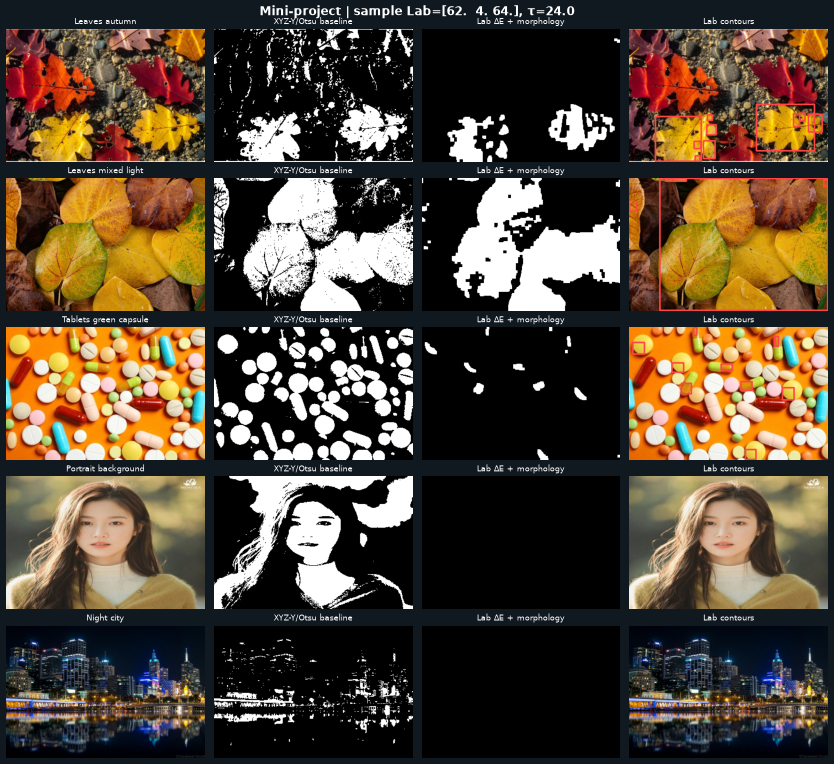

In [24]:
# Mini-project color detector: calibrate one yellow-green leaf sample, then test on 5 images.
# Fixed sample ROI makes comparisons reproducible; change it or call pick_lab_mask for interactive use.
calibration=load_image("leaves3.png")
calibration_lab=cv2.cvtColor(calibration,cv2.COLOR_RGB2LAB).astype(np.float32)
calibration_lab[...,0]*=100/255; calibration_lab[...,1:]-=128
project_target=np.median(calibration_lab[210:260,200:250].reshape(-1,3),axis=0)
project_tau=24.0
project_names=[("Leaves autumn","leaves.png"),("Leaves mixed light","leaves3.png"),("Tablets green capsule","tablets4.png"),("Portrait background","anh_chan_dung.jpg"),("Night city","anh-bd-vi-tri.jpg")]
project_outputs=[]; kernel=np.ones((5,5),np.uint8)
for title,filename in project_names:
    im=cv2.resize(load_image(filename),(360,240),interpolation=cv2.INTER_AREA)
    xyzp=rgb_to_xyz_float(im); yp=np.clip(xyzp[...,1]*255,0,255).astype(np.uint8)
    _,my=cv2.threshold(yp,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    labp=xyz_to_lab_float(xyzp); distp=np.linalg.norm(labp-project_target,axis=2)
    ml=(distp<=project_tau).astype(np.uint8)*255
    ml=cv2.morphologyEx(cv2.morphologyEx(ml,cv2.MORPH_OPEN,kernel),cv2.MORPH_CLOSE,kernel)
    contours,_=cv2.findContours(ml,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    significant=[c for c in contours if cv2.contourArea(c)>=0.0007*im.shape[0]*im.shape[1]]
    boxed=im.copy()
    for c in significant: cv2.rectangle(boxed,cv2.boundingRect(c),(255,70,70),2)
    project_outputs.append((title,im,my,ml,boxed,len(significant)))
fig,axes=plt.subplots(5,4,figsize=(14,13),facecolor="#101820")
for row,(title,im,my,ml,boxed,nbox) in enumerate(project_outputs):
    for ax,image,name in zip(axes[row],[im,my,ml,boxed],[title,"XYZ-Y/Otsu baseline","Lab ΔE + morphology","Lab contours"]):
        ax.imshow(image,cmap="gray" if image.ndim==2 else None); ax.set_title(name,color="white",fontsize=9); ax.axis("off")
fig.suptitle(f"Mini-project | sample Lab={np.round(project_target,1)}, τ={project_tau}",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
for title,im,my,ml,boxed,nbox in project_outputs: print(f"{title}: Y={np.mean(my>0):.1%}, Lab={np.mean(ml>0):.1%}, large contours={nbox}")


### Đánh giá mini-project — ba ví dụ và hai ca khó

Với mẫu cố định và τ=24, diện tích mask Lab lần lượt là 11.0% trên `leaves.png`, 45.4% trên `leaves3.png`, 2.3% trên `tablets4.png`, 0% trên chân dung và 0% trên thành phố. Ba ảnh đầu có vùng gần màu mẫu; hai ảnh cuối là ca âm tính/khó, nơi mask rỗng là hợp lý. Sau khi giảm area cutoff contour xuống 0.07%, cell hiển thị các box ứng viên của lá và viên thuốc.

Đây là minh họa định tính, không chứng minh mọi box đúng vì bộ dữ liệu không có annotation. Tỷ lệ mask 45.4% trên `leaves3.png` cho thấy ΔE còn rộng và dễ gộp nhiều vùng; cần giảm τ hoặc dùng ROI/spatial constraint khi cần một chiếc lá riêng. Ánh sáng, màu nền và vật thể gần màu mẫu là failure modes chính.

## Tổng kết trả lời câu hỏi so sánh không gian màu

1. Gray đủ khi khác biệt chủ yếu là cường độ; thất bại với biên màu cùng độ sáng. Y tách thành phần độ chói tương đối tốt hơn cách nhìn RGB tùy ý nhưng vẫn chỉ là một vô hướng.
2. Lab có lợi khi đối tượng khác nền về màu cảm nhận, kể cả khi L* gần nhau; ΔE cho một khoảng cách màu duy nhất. Nó vẫn nhạy với white point, ánh sáng, mẫu màu và ngưỡng.
3. XYZ là hệ cơ sở để tách Y và chuyển tiếp tới Lab; K-means XYZ hữu ích làm đối chứng nhưng khoảng cách XYZ không gần đều cảm nhận.
4. RGB channel-wise equalization làm đổi quan hệ giữa các kênh; HSV-V/Lab-L* thường giữ màu tốt hơn. CLAHE hữu ích với chiếu sáng không đều nhưng có thể khuếch đại nhiễu.
5. Không có thuật toán thắng mọi ảnh. Chọn đặc trưng theo nguyên nhân phân biệt (độ sáng, hue, khoảng cách màu), xem mask/edge/label trực quan và hậu xử lý có kiểm soát.

## 4.8.3 — CLAHE đối chiếu trực tiếp với equalization toàn cục

Để cô lập ảnh hưởng của equalization toàn cục và CLAHE, cell áp dụng cả hai lên cùng V trong HSV và L* trong Lab. `clipLimit=2.0`, `tileGridSize=(8,8)` là cấu hình thử nghiệm cố định. Mỗi cặp hàng hiển thị ảnh kết quả và bản đồ kênh đã xử lý; đối chiếu vùng bóng/sáng cùng số liệu clipping và độ lệch chuẩn in dưới hình. CLAHE cân bằng cục bộ nên thường giữ chi tiết vùng tối tốt hơn, nhưng có thể khuếch đại nhiễu.

Chân dung Global V: std=73.6, clipping=0.7%
Chân dung CLAHE V: std=63.3, clipping=0.6%
Chân dung Global L*: std=73.7, clipping=0.4%
Chân dung CLAHE L*: std=60.7, clipping=0.0%
Phong cảnh Global V: std=73.6, clipping=1.8%
Phong cảnh CLAHE V: std=72.2, clipping=1.7%
Phong cảnh Global L*: std=73.5, clipping=0.5%
Phong cảnh CLAHE L*: std=69.5, clipping=0.4%


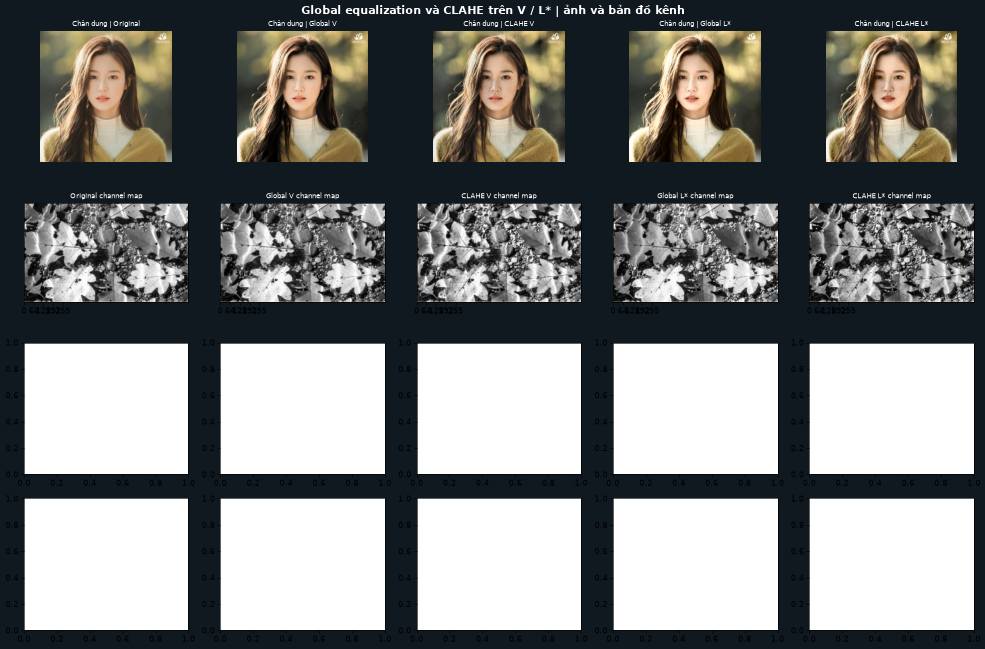

In [25]:
clahe_compare=[]
for title,im in [("Chân dung",portrait),("Phong cảnh",landscape)]:
    hsv=cv2.cvtColor(im,cv2.COLOR_RGB2HSV); h,s,v=cv2.split(hsv)
    v_eq=cv2.equalizeHist(v); v_clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(v)
    out_v_eq=cv2.cvtColor(cv2.merge([h,s,v_eq]),cv2.COLOR_HSV2RGB)
    out_v_clahe=cv2.cvtColor(cv2.merge([h,s,v_clahe]),cv2.COLOR_HSV2RGB)
    lab=cv2.cvtColor(im,cv2.COLOR_RGB2LAB); l,a,b=cv2.split(lab)
    l_eq=cv2.equalizeHist(l); l_clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(l)
    out_l_eq=cv2.cvtColor(cv2.merge([l_eq,a,b]),cv2.COLOR_LAB2RGB)
    out_l_clahe=cv2.cvtColor(cv2.merge([l_clahe,a,b]),cv2.COLOR_LAB2RGB)
    clahe_compare.append((title,[im,out_v_eq,out_v_clahe,out_l_eq,out_l_clahe],["Original","Global V","CLAHE V","Global L*","CLAHE L*"],[v,v_eq,v_clahe,l_eq,l_clahe]))
fig,axes=plt.subplots(4,5,figsize=(18,12),facecolor="#101820")
for row,(title,images,names,channels) in enumerate(clahe_compare):
    for col,(im,name,ch) in enumerate(zip(images,names,channels)):
        axes[row,col].imshow(im if row%2==0 else ch,cmap=None if row%2==0 else "gray",vmin=0 if row%2 else None,vmax=255 if row%2 else None)
        axes[row,col].set_title(f"{title} | {name}" if row%2==0 else f"{name} channel map",color="white",fontsize=9)
        axes[row,col].axis("off" if row%2==0 else "on")
        if row%2: axes[row,col].set_xticks([0,64,128,192,255]); axes[row,col].set_yticks([])
fig.suptitle("Global equalization và CLAHE trên V / L* | ảnh và bản đồ kênh",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
for title,images,names,channels in clahe_compare:
    for name,ch in zip(names[1:],channels[1:]): print(f"{title} {name}: std={np.std(ch):.1f}, clipping={(np.mean((ch==0)|(ch==255))):.1%}")


### Đánh giá CLAHE so với global equalization

Bảng/hình in ở trên đối照 cùng ảnh và cùng kênh. Global equalization trải histogram toàn ảnh; CLAHE thường tăng độ tương phản cục bộ ở vùng bóng mà hạn chế đẩy toàn bộ sáng/tối lên hai đầu. Độ lệch chuẩn cho biết độ tương phản tổng thể tăng hay giảm, còn pixel ở 0/255 là chỉ báo clipping thô; không dùng các chỉ số này riêng để chọn ảnh đẹp nhất. Trong hai ảnh thử, chọn CLAHE khi ánh sáng không đều; giảm `clipLimit` nếu nhiễu hoặc texture bị nhấn quá mạnh.

## 8.10.4 — Region growing trong RGB và Lab

Chọn một seed nằm trong lá vàng-xanh ở `leaves3.png`. Region growing 4-lân cận chỉ mở rộng pixel nếu khoảng cách màu tới seed không vượt ngưỡng; RGB dùng khoảng cách Euclid RGB, Lab dùng ΔEab. Hai ngưỡng khác đơn vị nên được chỉnh để mask có quy mô dễ so sánh, không phải cùng một con số. Morphology opening/closing làm sạch các lỗ nhỏ sau growing.

RGB region=2.6%; Lab region=28.5%


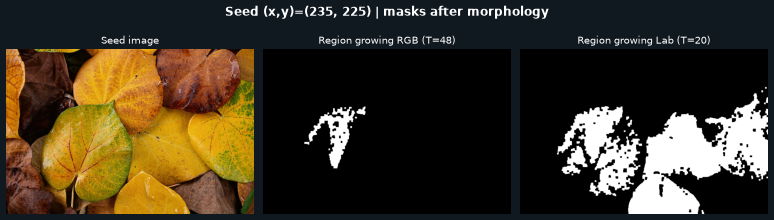

In [26]:
grow_img=load_image("leaves3.png")
seed=(235,225) # (x,y), nằm trong ROI calibration

def region_grow_seed(image,seed,space="Lab",threshold=20.0):
    if space=="Lab":
        feat=xyz_to_lab_float(rgb_to_xyz_float(image)).astype(np.float32)
    else: feat=image.astype(np.float32)
    x0,y0=seed; target=feat[y0,x0]
    distance=np.linalg.norm(feat-target,axis=2)
    allowed=distance<=threshold
    # Connected component enforces 4-connected growth from the selected seed.
    count,labels=cv2.connectedComponents(allowed.astype(np.uint8),connectivity=4)
    label=labels[y0,x0]
    return (labels==label).astype(np.uint8)*255
mask_grow_rgb=region_grow_seed(grow_img,seed,"RGB",threshold=48)
mask_grow_lab=region_grow_seed(grow_img,seed,"Lab",threshold=20)
kernel=np.ones((5,5),np.uint8)
mask_grow_rgb=cv2.morphologyEx(cv2.morphologyEx(mask_grow_rgb,cv2.MORPH_OPEN,kernel),cv2.MORPH_CLOSE,kernel)
mask_grow_lab=cv2.morphologyEx(cv2.morphologyEx(mask_grow_lab,cv2.MORPH_OPEN,kernel),cv2.MORPH_CLOSE,kernel)
fig,axes=plt.subplots(1,3,figsize=(13,4),facecolor="#101820")
for ax,im,title in zip(axes,[grow_img,mask_grow_rgb,mask_grow_lab],["Seed image","Region growing RGB (T=48)","Region growing Lab (T=20)"]): ax.imshow(im,cmap="gray" if im.ndim==2 else None); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle(f"Seed (x,y)={seed} | masks after morphology",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
print(f"RGB region={np.mean(mask_grow_rgb>0):.1%}; Lab region={np.mean(mask_grow_lab>0):.1%}")


### Kết quả region growing

Mask RGB thường nhạy hơn với thay đổi sáng và bóng vì cả ba kênh cường độ cùng đổi; Lab dùng ΔE nên có thể gom màu gần cảm nhận hơn và tách vùng vật liệu khác màu. Nếu vùng lá có màu biến thiên mạnh, seed-based fixed threshold vẫn có thể ngắt vùng; cần nhiều seed, cập nhật màu trung bình, hoặc adaptive threshold. Tỉ lệ vùng được in để đối chiếu: RGB growing 2.6%, Lab growing 28.5%. Lab bao phủ rộng hơn đáng kể nên ngưỡng 20 cần giảm nếu mục tiêu là một lá riêng.

## 8.4 — Boundary-based segmentation: biên màu → contour → vùng tô

Dùng Canny trên L*, a*, b* rồi hợp các cạnh, đóng khe biên bằng morphology, tìm contour ngoài và tô vùng kín. Hình so sánh biên, biên sau closing, contour, và vùng kết quả. Pipeline này minh họa đầy đủ bước boundary-to-region; nếu biên không kín hoặc texture bên trong tạo nhiều contour, vùng tô có thể tràn/lẫn và cần lọc contour theo diện tích/vị trí.

filled area=92.8%; contours=1


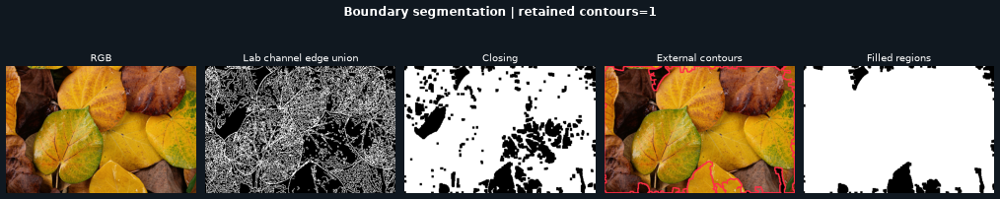

In [27]:
boundary_img=cv2.resize(load_image("leaves3.png"),(420,280),interpolation=cv2.INTER_AREA)
lab_b=cv2.cvtColor(boundary_img,cv2.COLOR_RGB2LAB)
edge_l=cv2.Canny(lab_b[...,0],45,100); edge_a=cv2.Canny(lab_b[...,1],35,85); edge_b=cv2.Canny(lab_b[...,2],35,85)
edge_color=cv2.bitwise_or(edge_l,cv2.bitwise_or(edge_a,edge_b))
edge_closed=cv2.morphologyEx(edge_color,cv2.MORPH_CLOSE,np.ones((5,5),np.uint8),iterations=1)
contours,_=cv2.findContours(edge_closed,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
contours=[c for c in contours if cv2.contourArea(c)>0.002*boundary_img.shape[0]*boundary_img.shape[1]]
filled=np.zeros(edge_closed.shape,np.uint8); cv2.drawContours(filled,contours,-1,255,cv2.FILLED)
contour_view=boundary_img.copy(); cv2.drawContours(contour_view,contours,-1,(255,45,70),2)
fig,axes=plt.subplots(1,5,figsize=(17,4),facecolor="#101820")
for ax,im,title,cmap in zip(axes,[boundary_img,edge_color,edge_closed,contour_view,filled],["RGB","Lab channel edge union","Closing","External contours","Filled regions"],[None,"gray","gray",None,"gray"]): ax.imshow(im,cmap=cmap); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle(f"Boundary segmentation | retained contours={len(contours)}",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
print(f"filled area={np.mean(filled>0):.1%}; contours={len(contours)}")


### Đánh giá boundary-based segmentation

Closing giúp nối khe ngắn nhưng không thể tự sửa biên hở lớn; lần chạy này tạo một contour ngoài bao 92.8% ảnh. Đây là thất bại: texture nối với viền khung làm vùng tô gộp nền với lá. Tỷ lệ vùng tô và số contour ở output giúp nhận ra over-segmentation/under-segmentation. So với ΔE threshold, phương pháp này dùng hình dạng biên và không cần màu mẫu, nhưng nhạy với texture lá và tham số Canny/morphology.

## 3.3 — Định lượng ảnh ban ngày và ban đêm

Ngoài histogram đã chuẩn hóa để so hình dạng, cell dưới đo mean/median Value và phần pixel tối (`V<64`) của ảnh lá ban ngày và cảnh thành phố ban đêm. Phần này trả lời trực tiếp yêu cầu so sánh hai histogram, đồng thời nhắc rằng histogram là thống kê toàn ảnh và không giữ vị trí không gian.

In [28]:
for title,im in [("Ban ngày — leaves.png",img1),("Ban đêm — city",img2)]:
    hsv=cv2.cvtColor(im,cv2.COLOR_RGB2HSV); v=hsv[...,2]
    print(f"{title}: mean V={v.mean():.1f}, median V={np.median(v):.1f}, V<64={np.mean(v<64):.1%}")


Ban ngày — leaves.png: mean V=128.4, median V=127.0, V<64=24.7%
Ban đêm — city: mean V=62.3, median V=38.0, V<64=67.0%


### Kết quả 3.3 — Histogram ngày/đêm

Histogram Hue/RGB và số liệu V cho thấy cảnh thành phố ban đêm có phân bố sáng lệch về phía pixel tối hơn ảnh lá chụp ngoài trời. Histogram ảnh lá có các đỉnh của sắc đỏ/cam/vàng/xanh; cảnh đêm có các pixel nền tối cùng đèn nhiều màu. Vì histogram chuẩn hóa theo tổng pixel nên có thể so hình dạng dù độ phân giải ảnh khác nhau. Histogram không cho biết màu nào nằm ở đâu trong cảnh.

## 4.8 — Định lượng giữ màu sau cân bằng

Dùng hai ảnh chân dung/phong cảnh, tính ΔEab trung bình so ảnh gốc và độ đổi Hue trung vị (chỉ pixel có saturation đủ lớn) sau ba phương pháp: equalize từng kênh RGB, HSV-V và Lab-L*. Đây là chỉ báo số học hỗ trợ đánh giá bằng mắt; OpenCV Lab 8-bit và phép đổi màu có xấp xỉ nên các số không phải đánh giá chất lượng cảm nhận chuẩn hóa.

In [29]:
def lab_opencv_float(im):
    l=cv2.cvtColor(im,cv2.COLOR_RGB2LAB).astype(np.float32); l[...,0]*=100/255; l[...,1:]-=128; return l
for title,im in [("Portrait",portrait),("Landscape",landscape)]:
    rgb_eq=cv2.merge([cv2.equalizeHist(c) for c in cv2.split(im)])
    hsv=cv2.cvtColor(im,cv2.COLOR_RGB2HSV); h,s,v=cv2.split(hsv)
    hsv_eq=cv2.cvtColor(cv2.merge([h,s,cv2.equalizeHist(v)]),cv2.COLOR_HSV2RGB)
    lab=cv2.cvtColor(im,cv2.COLOR_RGB2LAB); l,a,b=cv2.split(lab)
    lab_eq=cv2.cvtColor(cv2.merge([cv2.equalizeHist(l),a,b]),cv2.COLOR_LAB2RGB)
    h0=h.astype(np.int16); valid=s>40
    for method,out in [("RGB channels",rgb_eq),("HSV-V",hsv_eq),("Lab-L*",lab_eq)]:
        lab_delta=np.linalg.norm(lab_opencv_float(out)-lab_opencv_float(im),axis=2)
        h1=cv2.cvtColor(out,cv2.COLOR_RGB2HSV)[...,0].astype(np.int16)
        dh=np.abs(h1-h0); dh=np.minimum(dh,180-dh)
        print(f"{title} {method}: mean ΔEab={lab_delta.mean():.2f}, median |ΔH|={np.median(dh[valid]):.1f}")


Portrait RGB channels: mean ΔEab=21.03, median |ΔH|=27.0
Portrait HSV-V: mean ΔEab=7.15, median |ΔH|=0.0
Portrait Lab-L*: mean ΔEab=7.32, median |ΔH|=0.0
Landscape RGB channels: mean ΔEab=38.33, median |ΔH|=31.0
Landscape HSV-V: mean ΔEab=1.44, median |ΔH|=0.0
Landscape Lab-L*: mean ΔEab=12.61, median |ΔH|=1.0


### Kết quả 4.8 — Cân bằng histogram và màu tự nhiên

Đối chiếu chỉ số ΔEab/Hue với bảng hình ảnh 4.4: cân bằng RGB thay đổi riêng các kênh nên thường gây chệch màu lớn hơn; HSV-V giữ Hue/Saturation đầu vào nhưng màu hiển thị vẫn thay đổi do gamut và phép chuyển đổi RGB; Lab-L* chỉ chỉnh sáng theo kênh L* nhưng cũng có thể làm màu nhìn khác. Ưu tiên đánh giá ảnh chân dung bằng màu da và vùng sáng, ảnh phong cảnh bằng màu lá/bầu trời; không kết luận chỉ từ độ tương phản histogram. Các trị số cụ thể nằm ngay trong output cell phía trên.

## 7.12.3 — Otsu trên khoảng cách màu ΔE

Đề gợi ý chọn màu mẫu, tính khoảng cách màu rồi tự động xác định ngưỡng bằng Otsu. Cell dưới dùng cùng ROI mẫu trên lá, chuẩn hóa bản đồ khoảng cách về 8-bit, chạy Otsu inverse (gần mẫu = foreground), rồi đối chiếu mask Otsu tự động với τ lấy từ ROI. Otsu trên khoảng cách có thể gộp nhiều khoảng cách vào một lớp và không đảm bảo mask mục tiêu hoàn hảo; xem cả map ΔE lẫn kết quả.

Otsu distance foreground=62.4%; ROI tau foreground=27.1%


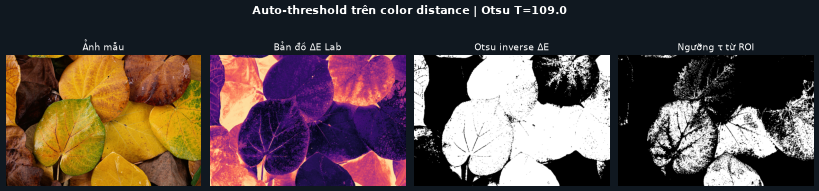

In [30]:
dist_u8=cv2.normalize(dist_roi,None,0,255,cv2.NORM_MINMAX).astype(np.uint8)
t_dist,mask_dist_otsu=cv2.threshold(dist_u8,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
fig,axes=plt.subplots(1,4,figsize=(15,4),facecolor="#101820")
for ax,im,title,cmap in zip(axes,[leaf,dist_roi,mask_dist_otsu,mask_delta],["Ảnh mẫu","Bản đồ ΔE Lab","Otsu inverse ΔE","Ngưỡng τ từ ROI"],[None,"magma","gray","gray"]): ax.imshow(im,cmap=cmap); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle(f"Auto-threshold trên color distance | Otsu T={t_dist}",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
print(f"Otsu distance foreground={np.mean(mask_dist_otsu>0):.1%}; ROI tau foreground={np.mean(mask_delta>0):.1%}")


### Phân tích Otsu trên ΔE

Otsu tự chọn một T trên bản đồ ΔE chuẩn hóa; kết quả foreground và ROI threshold in ngay dưới hình. Otsu chọn T=109/255 và cho foreground 62.4%, rộng hơn ROI threshold 27.1%; phân bố khoảng cách không tạo hai lớp cân bằng. Otsu không cần nhập τ nhưng tạo mask rộng hơn trong ảnh này. Nếu nền có nhiều pixel xa màu mẫu, inverse Otsu thường tách được nhóm gần màu; nếu vật thể chiếm phần lớn ảnh hoặc nền có màu tương tự, Otsu có thể chọn ngưỡng quá rộng. ROI-calibrated τ có ý nghĩa kiểm soát trực quan hơn khi đã biết biến thiên màu bên trong đối tượng.

## 7. Otsu hai bước S→V và câu hỏi khi chọn kênh

Otsu trên S giữ pixel có màu bão hòa, sau đó Otsu trên V trong tập ứng viên tách vùng sáng/tối. Cách hai bước hợp lý khi vật thể có màu rõ nhưng nền gồm nhiều vùng gần xám; nếu mục tiêu cũng ít bão hòa, bước S sẽ loại nhầm đối tượng. Cell áp dụng trên `leaves3.png` và hiển thị từng mask để thấy lỗi truyền qua pipeline.

Otsu S candidates=68.5%; two-stage mask=49.2%


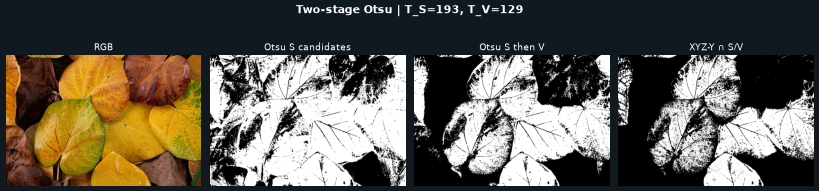

In [33]:
hsv_two=cv2.cvtColor(leaf,cv2.COLOR_RGB2HSV); s_two=hsv_two[...,1]; v_two=hsv_two[...,2]
t_s,mask_s=cv2.threshold(s_two,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
candidates=v_two[mask_s>0]
if candidates.size:
    t_v,mask_v_candidate=cv2.threshold(candidates.reshape(-1,1),0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    mask_sv=np.zeros_like(mask_s); mask_sv[(mask_s>0)&(v_two>t_v)]=255
else: t_v=0; mask_sv=np.zeros_like(mask_s)
fig,axes=plt.subplots(1,4,figsize=(15,4),facecolor="#101820")
for ax,im,title in zip(axes,[leaf,mask_s,mask_sv,cv2.bitwise_and(mask_y,mask_sv)],["RGB","Otsu S candidates","Otsu S then V","XYZ-Y ∩ S/V"]): ax.imshow(im,cmap="gray" if im.ndim==2 else None); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle(f"Two-stage Otsu | T_S={t_s:.0f}, T_V={t_v:.0f}",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
print(f"Otsu S candidates={np.mean(mask_s>0):.1%}; two-stage mask={np.mean(mask_sv>0):.1%}")


### Kết quả Otsu hai bước

Otsu S trước tiên loại pixel ít bão hòa; V chỉ được threshold trong tập còn lại. Otsu S giữ 68.5% pixel làm candidates; bước V giữ 49.2% ở mask cuối. Đây không phải công thức phổ quát: khi đối tượng tối/ít bão hòa hoặc nền cũng bão hòa, mask S sẽ làm mất đối tượng hoặc giữ nền; khi ánh sáng không đều, threshold toàn cục trên V có thể tiếp tục sai.

## 7.3/11 — Khử nhiễu trên độ sáng Y và L*

Để tách ảnh hưởng của nhiễu màu khỏi cấu trúc ảnh, thêm nhiễu Gaussian có seed cố định lên ảnh lá rồi lọc Gaussian và median riêng trên kênh Y (XYZ) và L* (Lab). So sánh ảnh kênh trước/sau và MAE so với kênh sạch. Mức MAE nhỏ hơn không đồng nghĩa ảnh tốt hơn nếu chi tiết biên bị mờ; đọc cùng các panel.

MAE Y noisy=0.0339, Gaussian=0.0249, median=0.0298
MAE L* noisy=3.93, Gaussian=3.02, median=3.54


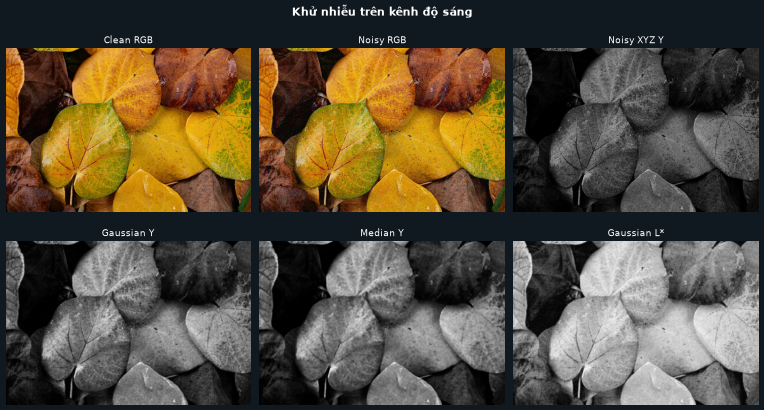

In [34]:
rng=np.random.default_rng(17)
clean=load_image("leaves3.png")
noisy=np.clip(clean.astype(np.float32)+rng.normal(0,18,clean.shape),0,255).astype(np.uint8)
xyz_clean=rgb_to_xyz_float(clean); xyz_noisy=rgb_to_xyz_float(noisy)
y_clean=xyz_clean[...,1]; y_noisy=xyz_noisy[...,1]
lab_clean=xyz_to_lab_float(xyz_clean); lab_noisy=xyz_to_lab_float(xyz_noisy)
l_clean=lab_clean[...,0]; l_noisy=lab_noisy[...,0]
y_gauss=cv2.GaussianBlur(y_noisy.astype(np.float32),(5,5),1.0); y_median=cv2.medianBlur(np.clip(y_noisy*255,0,255).astype(np.uint8),5).astype(np.float32)/255
l_gauss=cv2.GaussianBlur(l_noisy.astype(np.float32),(5,5),1.0); l_median=cv2.medianBlur(np.clip(l_noisy*255/100,0,255).astype(np.uint8),5).astype(np.float32)*100/255
fig,axes=plt.subplots(2,3,figsize=(14,8),facecolor="#101820")
for ax,im,title in zip(axes[0],[clean,noisy,y_noisy],["Clean RGB","Noisy RGB","Noisy XYZ Y"]): ax.imshow(im,cmap="gray" if im.ndim==2 else None); ax.set_title(title,color="white"); ax.axis("off")
for ax,im,title in zip(axes[1],[y_gauss,y_median,l_gauss],["Gaussian Y","Median Y","Gaussian L*"]): ax.imshow(im,cmap="gray"); ax.set_title(title,color="white"); ax.axis("off")
fig.suptitle("Khử nhiễu trên kênh độ sáng",color="white",fontsize=14,fontweight="bold"); fig.tight_layout(); plt.show()
print(f"MAE Y noisy={np.mean(np.abs(y_noisy-y_clean)):.4f}, Gaussian={np.mean(np.abs(y_gauss-y_clean)):.4f}, median={np.mean(np.abs(y_median-y_clean)):.4f}")
print(f"MAE L* noisy={np.mean(np.abs(l_noisy-l_clean)):.2f}, Gaussian={np.mean(np.abs(l_gauss-l_clean)):.2f}, median={np.mean(np.abs(l_median-l_clean)):.2f}")


### Đánh giá lọc nhiễu

Median thường bảo toàn cạnh tốt hơn Gaussian khi có nhiễu xung; Gaussian làm trơn đồng đều nhưng cũng làm mờ gân lá. So MAE các kênh Y/L*: nhiễu→Gaussian→median lần lượt là Y 0.0339→0.0249→0.0298; L* 3.93→3.02→3.54. Gaussian giảm MAE nhiều nhất ở thí nghiệm này, nhưng vẫn cần kiểm tra gân lá có bị mờ không. Thí nghiệm này dùng nhiễu Gaussian nhân tạo, nên không khẳng định bộ lọc nào tốt nhất cho nhiễu cảm biến thực tế.